### Forecast data

In [121]:
import matplotlib.pyplot as plt
from cycler import cycler

# Define a muted palette that complements the poster colors
palette = [
    "#807098",  # Dusty purple
    "#526F91",  # Muted blue
    "#B18A32",  # Muted gold
    "#527B67",  # Sage green
    "#B66F58",  # Terracotta
    "#9C6481",  # Dusty rose
    "#49858A",  # Muted teal
    "#817565",  # Warm taupe
]

# Set the default color cycle for newly created plots
plt.rcParams["axes.prop_cycle"] = cycler(color=palette)

# Keep each model's color consistent regardless of plotting order
colors = dict(zip([
    "dmi_harmonie_arome_europe",
    "metno_nordic",
    "ecmwf_ifs025",
    "ecmwf_aifs025_single",
    "gfs_global",
    "ecmwf_ifs",
    "dmi_seamless",
    "gfs_seamless",
], palette))

colors["blend"] = "#35313D"
# Readable plot defaults for notebook and poster exports.
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


In [122]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [123]:
from pathlib import Path
import sys
import importlib
import numpy as np
import pandas as pd

notebook_dir = Path.cwd()
sys.path.insert(0, str(notebook_dir))

import functions_new
importlib.reload(functions_new)

# New pandas versions no longer allow dropna=True inside stack().
def _interval_values_pandas_compatible(forecast, first_hour, last_hour):
    columns = [
        lead for lead in forecast.columns
        if first_hour <= lead <= last_hour
    ]
    if not columns:
        return pd.Series(dtype=float)

    subset = forecast.loc[:, columns].replace([np.inf, -np.inf], np.nan).copy()
    subset.index.name = "valid_time"
    subset.columns.name = "lead_time_h"
    values = subset.stack().dropna()
    values.index.names = ["valid_time", "lead_time_h"]
    return values

functions_new._interval_values = _interval_values_pandas_compatible

from functions_new import (
    get_dmi_ghi,
    resample_dmi_ghi_hourly,
    get_forecast_data,
    calculate_forecast_metrics,
    calculate_overall_metrics,
    our_blend_by_lead_time,
    our_blended_forecasts,
    fit_blend_weights_by_lead_time,
)

print("Using functions from:", Path(functions_new.__file__).resolve())


Using functions from: C:\Users\matil\OneDrive\Skrivebord\Python\Solar forecasting\solar_forecast_project\notebooks\functions_new.py


In [124]:
#Get raw DMI measurements 
dmi_data = get_dmi_ghi(start="2025-11-09",end="2026-11-24", station="06019")

#Resample to hourly measurements
hourly_dmi = resample_dmi_ghi_hourly(dmi_data)

In [125]:
# Load the forecast files and match them with hourly measurements.
forecast_data = get_forecast_data(
    hourly_dmi,
    start="2026-11-09",
)


In [126]:
dmi_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 54649 entries, 2025-11-09 00:00:00+00:00 to 2026-11-24 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     54649 non-null  float64
dtypes: float64(1)
memory usage: 853.9 KB


## Filter night away using solpos

Find solar position, in order to filter night data points away

In [127]:
#Calculate solar position for forecast valid times
timestamps = pd.DatetimeIndex(pd.concat(forecast_data.values())["valid_time"].unique())

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solar_elevation = solpos["apparent_elevation"]

#Only keeping the daylight hours
daylight_times = timestamps[solar_elevation.to_numpy() > 0]

df_forecast_day = {
    model: df[df["valid_time"].isin(daylight_times)].copy()
    for model, df in forecast_data.items()
}

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function for alle forecast models, such that the index becomes just the time and the lead time become the columns. And the resulting dataframes are stored in a dictionary for each model and can be plotted.

In [128]:
#Unstacking all forecast models
forecast_unstacked = {
    model: df.set_index(["valid_time", "lead_time_h"])["ghi_forecast"].unstack()
    for model, df in df_forecast_day.items()
}

We can add an overview of the data for each model, to help identify differences in forecast horizons and available data. 

In [129]:
for model, df in forecast_data.items():
    print(
        model,
        "| Forecasts:", len(df),
        "| Matched measurements:", df["ghi_measured"].notna().sum(),
        "| Max horizon:", df["lead_time_h"].max()
    )

dmi_harmonie_arome_europe | Forecasts: 23166 | Matched measurements: 17014 | Max horizon: 56.0
metno_nordic | Forecasts: 23709 | Matched measurements: 17372 | Max horizon: 57.0
ecmwf_ifs025 | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0
ecmwf_aifs025_single | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0
gfs_global | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0
ecmwf_ifs | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0
dmi_seamless | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0
gfs_seamless | Forecasts: 65250 | Matched measurements: 40131 | Max horizon: 167.0


In [130]:
scores = calculate_forecast_metrics(
    forecast_unstacked,
    hourly_dmi,
)


In [131]:
# RMSE and bias are used as the forecast error metrics.


### 

In [132]:
# Compact overall comparison using the same metrics as the assignment.
overall_scores = calculate_overall_metrics(scores)
overall_scores = overall_scores[["model", "rmse", "bias", "n"]].sort_values("rmse")
display(
    overall_scores.style
    .format({"rmse": "{:.1f}", "bias": "{:.1f}", "n": "{:.0f}"})
)


,model,rmse,bias,n
2,ecmwf_aifs025_single,38.0,0.8,12867
4,ecmwf_ifs025,38.9,-6.3,12867
5,gfs_global,39.7,2.3,12867
6,gfs_seamless,39.7,2.3,12867
3,ecmwf_ifs,40.0,-6.6,12867
7,metno_nordic,41.4,1.8,5522
1,dmi_seamless,43.9,-4.8,12867
0,dmi_harmonie_arome_europe,45.8,-3.0,5438


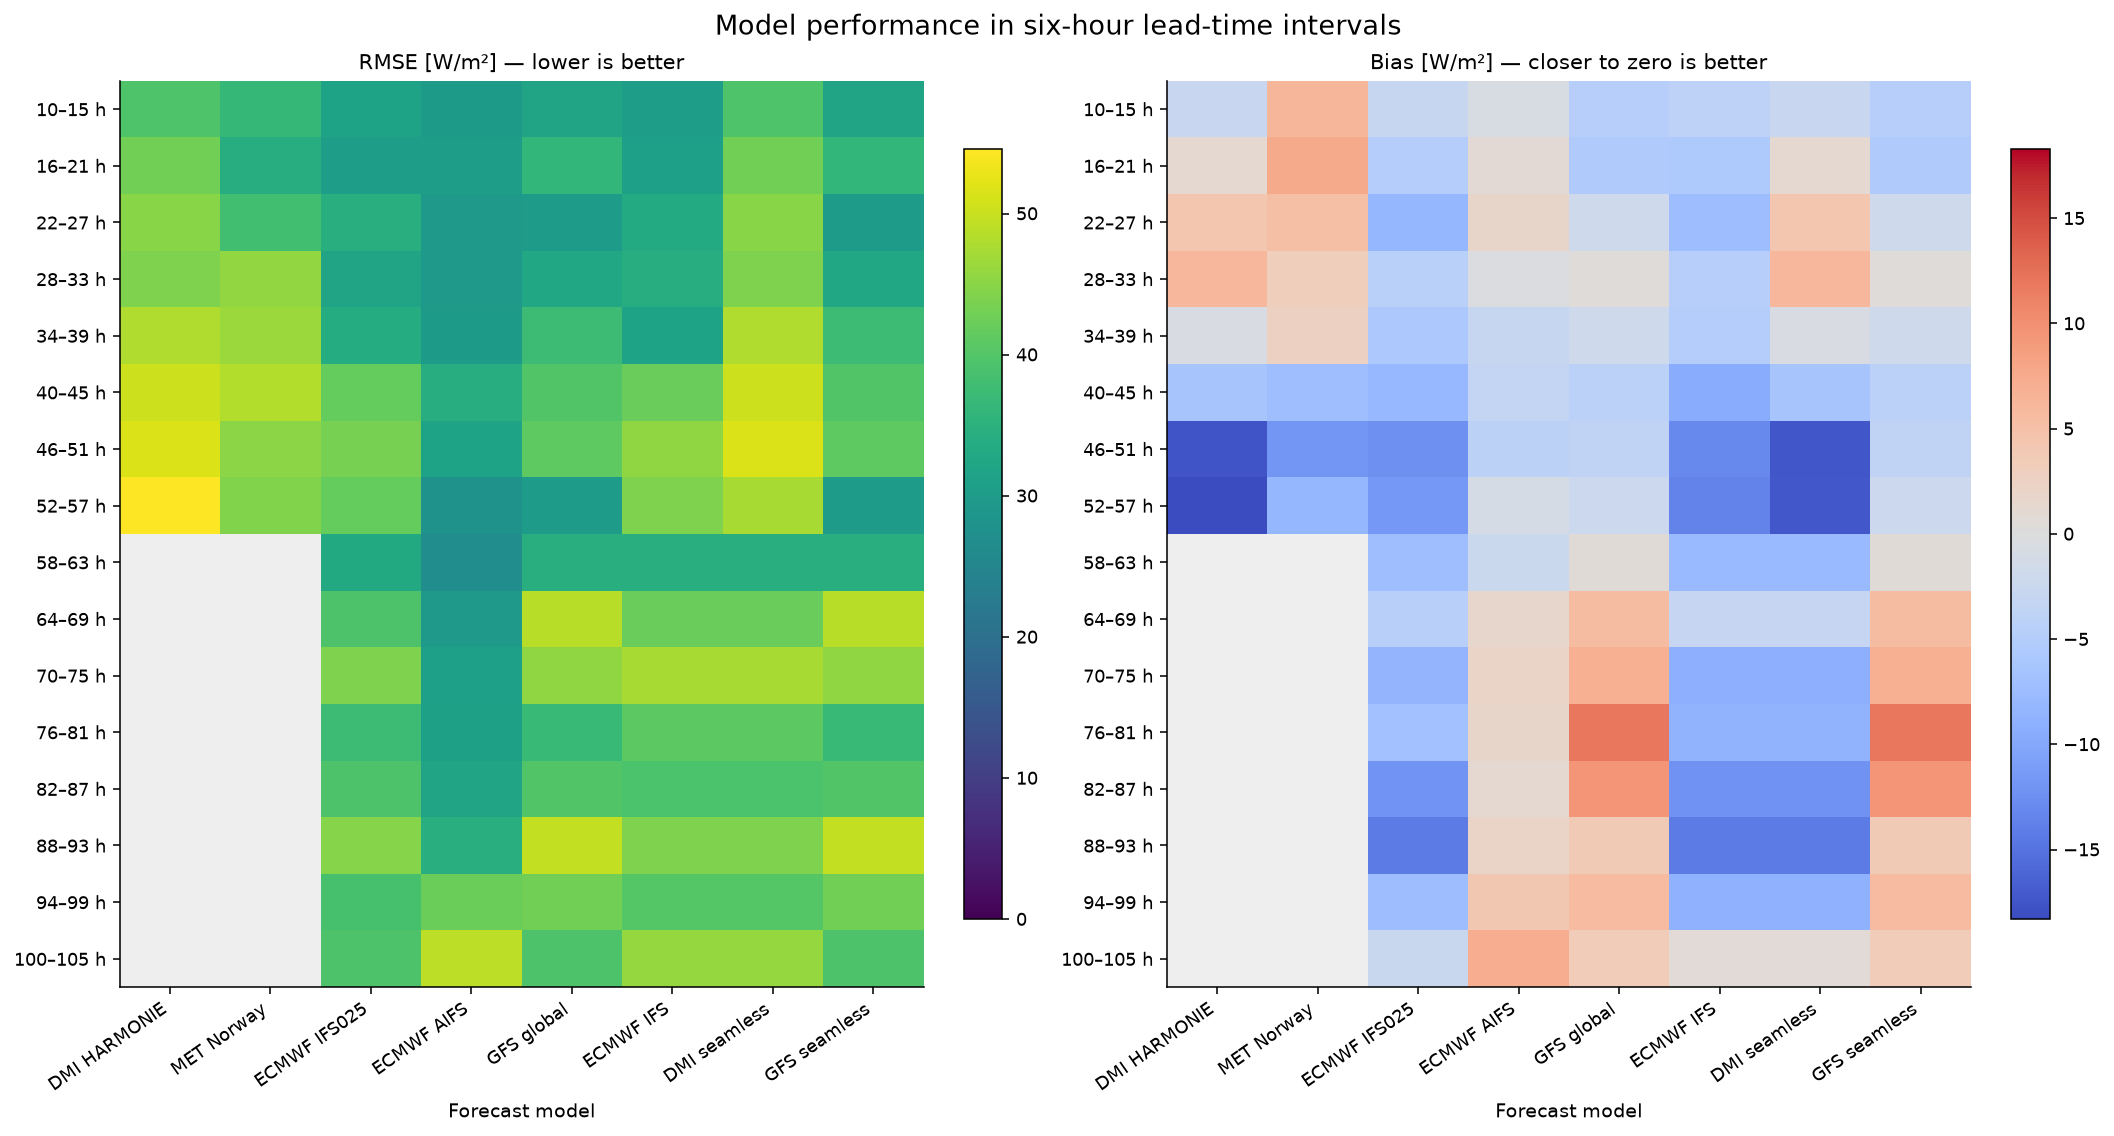

In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep the same lead-time range used by the blend.
intervals = [(first, first + 5) for first in range(10, 106, 6)]
model_names = list(forecast_unstacked)
measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)

rmse_rows = {}
bias_rows = {}
count_rows = {}

for first, last in intervals:
    leads = list(range(first, last + 1))
    predictions = {}

    for model, forecast in forecast_unstacked.items():
        subset = forecast.reindex(columns=leads).replace([np.inf, -np.inf], np.nan)
        if subset.notna().any().any():
            subset = subset.copy()
            subset.index.name = "valid_time"
            subset.columns.name = "lead_time_h"
            predictions[model] = subset.stack().dropna()

    if not predictions:
        continue

    paired = pd.concat(predictions, axis=1).dropna()
    observations = measured.reindex(
        paired.index.get_level_values("valid_time")
    )
    observations.index = paired.index
    valid = observations.notna()
    paired = paired.loc[valid]
    observations = observations.loc[valid]

    if paired.empty:
        continue

    # Positive bias means the forecast is below the measured GHI.
    errors = paired.rsub(observations, axis=0)
    label = f"{first}–{last} h"
    rmse_rows[label] = np.sqrt(errors.pow(2).mean())
    bias_rows[label] = errors.mean()
    count_rows[label] = errors.count()

interval_labels = [f"{first}–{last} h" for first, last in intervals]
rmse_table = pd.DataFrame(rmse_rows).T.reindex(
    index=interval_labels, columns=model_names
)
bias_table = pd.DataFrame(bias_rows).T.reindex(
    index=interval_labels, columns=model_names
)
count_table = pd.DataFrame(count_rows).T.reindex(
    index=interval_labels, columns=model_names
)

# Hide cells with limited support, while retaining counts in count_table.
min_samples_for_plot = 30
rmse_plot = rmse_table.mask(count_table < min_samples_for_plot)
bias_plot = bias_table.mask(count_table < min_samples_for_plot)

short_names = {
    "dmi_harmonie_arome_europe": "DMI HARMONIE",
    "metno_nordic": "MET Norway",
    "ecmwf_ifs025": "ECMWF IFS025",
    "ecmwf_aifs025_single": "ECMWF AIFS",
    "gfs_global": "GFS global",
    "ecmwf_ifs": "ECMWF IFS",
    "dmi_seamless": "DMI seamless",
    "gfs_seamless": "GFS seamless",
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 8),
    gridspec_kw={"width_ratios": [1, 1]},
    constrained_layout=True,
)

for ax, table, title, cmap_name, symmetric in [
    (axes[0], rmse_plot, "RMSE [W/m²] — lower is better", "viridis", False),
    (axes[1], bias_plot, "Bias [W/m²] — closer to zero is better", "coolwarm", True),
]:
    values = table.to_numpy(dtype=float)
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("#eeeeee")
    if symmetric:
        finite = np.abs(values[np.isfinite(values)])
        limit = max(finite.max(), 1) if len(finite) else 1
        image = ax.imshow(
            values, aspect="auto", interpolation="nearest", cmap=cmap,
            norm=plt.Normalize(vmin=-limit, vmax=limit),
        )
    else:
        finite = values[np.isfinite(values)]
        vmax = finite.max() if len(finite) else 1
        image = ax.imshow(
            values, aspect="auto", interpolation="nearest", cmap=cmap,
            vmin=0, vmax=max(vmax, 1),
        )
    ax.set_xticks(np.arange(len(model_names)))
    ax.set_xticklabels([short_names.get(model, model) for model in model_names], rotation=35, ha="right")
    ax.set_yticks(np.arange(len(interval_labels)))
    ax.set_yticklabels(interval_labels)
    ax.set_title(title)
    ax.set_xlabel("Forecast model")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.85)

fig.suptitle("Model performance in six-hour lead-time intervals", fontsize=14)
plt.show()


In [134]:
max_evaluated_lead = (
    scores.loc[scores["n"] > 0]
    .groupby("model")["lead_time_h"]
    .max()
)

print(max_evaluated_lead)

model
dmi_harmonie_arome_europe     56.0
dmi_seamless                 159.0
ecmwf_aifs025_single         159.0
ecmwf_ifs                    159.0
ecmwf_ifs025                 159.0
gfs_global                   159.0
gfs_seamless                 159.0
metno_nordic                  57.0
Name: lead_time_h, dtype: float64


### Different daily profiles

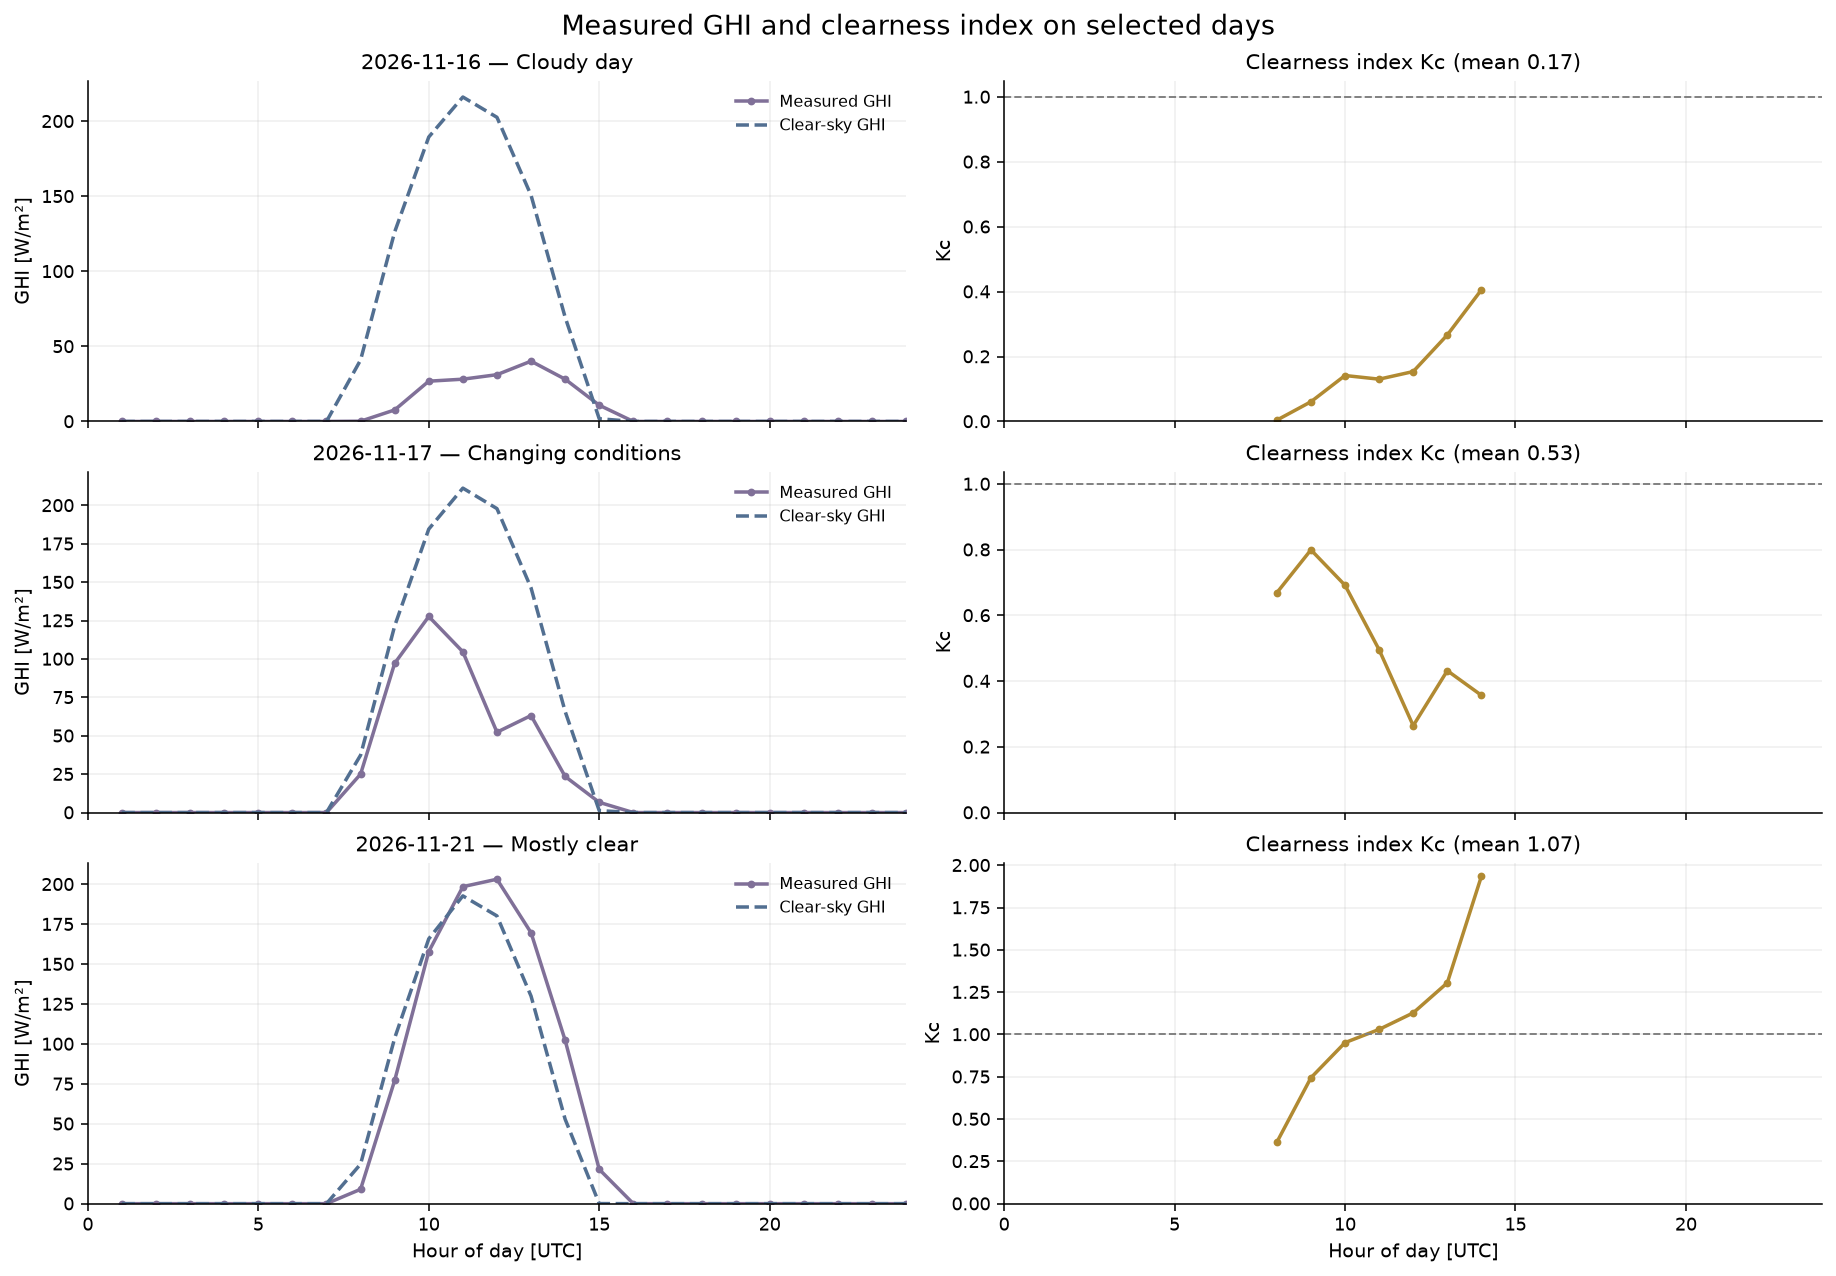

In [135]:
import numpy as np
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}
solar_site = pvlib.location.Location(
    latitude=56.93,
    longitude=8.6412,
    tz="UTC",
    name="DMI station 06019",
)

fig, axes = plt.subplots(
    len(profile_days), 2,
    figsize=(13, 9),
    sharex=True,
    constrained_layout=True,
)

for row, (date, description) in enumerate(profile_days.items()):
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    daily_ghi = hourly_dmi.loc[
        (hourly_dmi.index > start) & (hourly_dmi.index <= end),
        "ghi_measured",
    ].replace([np.inf, -np.inf], np.nan).dropna()
    clear_sky_ghi = solar_site.get_clearsky(
        daily_ghi.index, model="ineichen"
    )["ghi"]
    daytime = clear_sky_ghi > 20
    clearness_index = (
        daily_ghi.loc[daytime] / clear_sky_ghi.loc[daytime]
    ).replace([np.inf, -np.inf], np.nan).dropna()

    hour = (daily_ghi.index - start).total_seconds() / 3600
    clear_sky_hour = (clear_sky_ghi.index - start).total_seconds() / 3600
    kc_hour = (clearness_index.index - start).total_seconds() / 3600
    ax_ghi, ax_kc = axes[row]
    ax_ghi.plot(hour, daily_ghi, marker="o", markersize=3, linewidth=1.8, label="Measured GHI")
    ax_ghi.plot(clear_sky_hour, clear_sky_ghi, linestyle="--", linewidth=1.8, label="Clear-sky GHI")
    ax_ghi.set_title(f"{date} — {description}")
    ax_ghi.set_ylabel("GHI [W/m²]")
    ax_ghi.set_ylim(bottom=0)
    ax_ghi.grid(alpha=0.2)
    ax_ghi.legend(frameon=False, fontsize=8)

    ax_kc.plot(kc_hour, clearness_index, marker="o", markersize=3, linewidth=1.8, color="#B18A32")
    ax_kc.axhline(1, color="grey", linestyle="--", linewidth=1)
    ax_kc.set_title(f"Clearness index Kc (mean {clearness_index.mean():.2f})")
    ax_kc.set_ylabel("Kc")
    ax_kc.set_ylim(bottom=0)
    ax_kc.grid(alpha=0.2)

for ax in axes[-1]:
    ax.set_xlabel("Hour of day [UTC]")
    ax.set_xlim(0, 24)
fig.suptitle("Measured GHI and clearness index on selected days", fontsize=14)
plt.show()


C:\Users\matil\AppData\Local\Temp\ipykernel_34132\555170679.py:38: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  comparison = pd.concat(


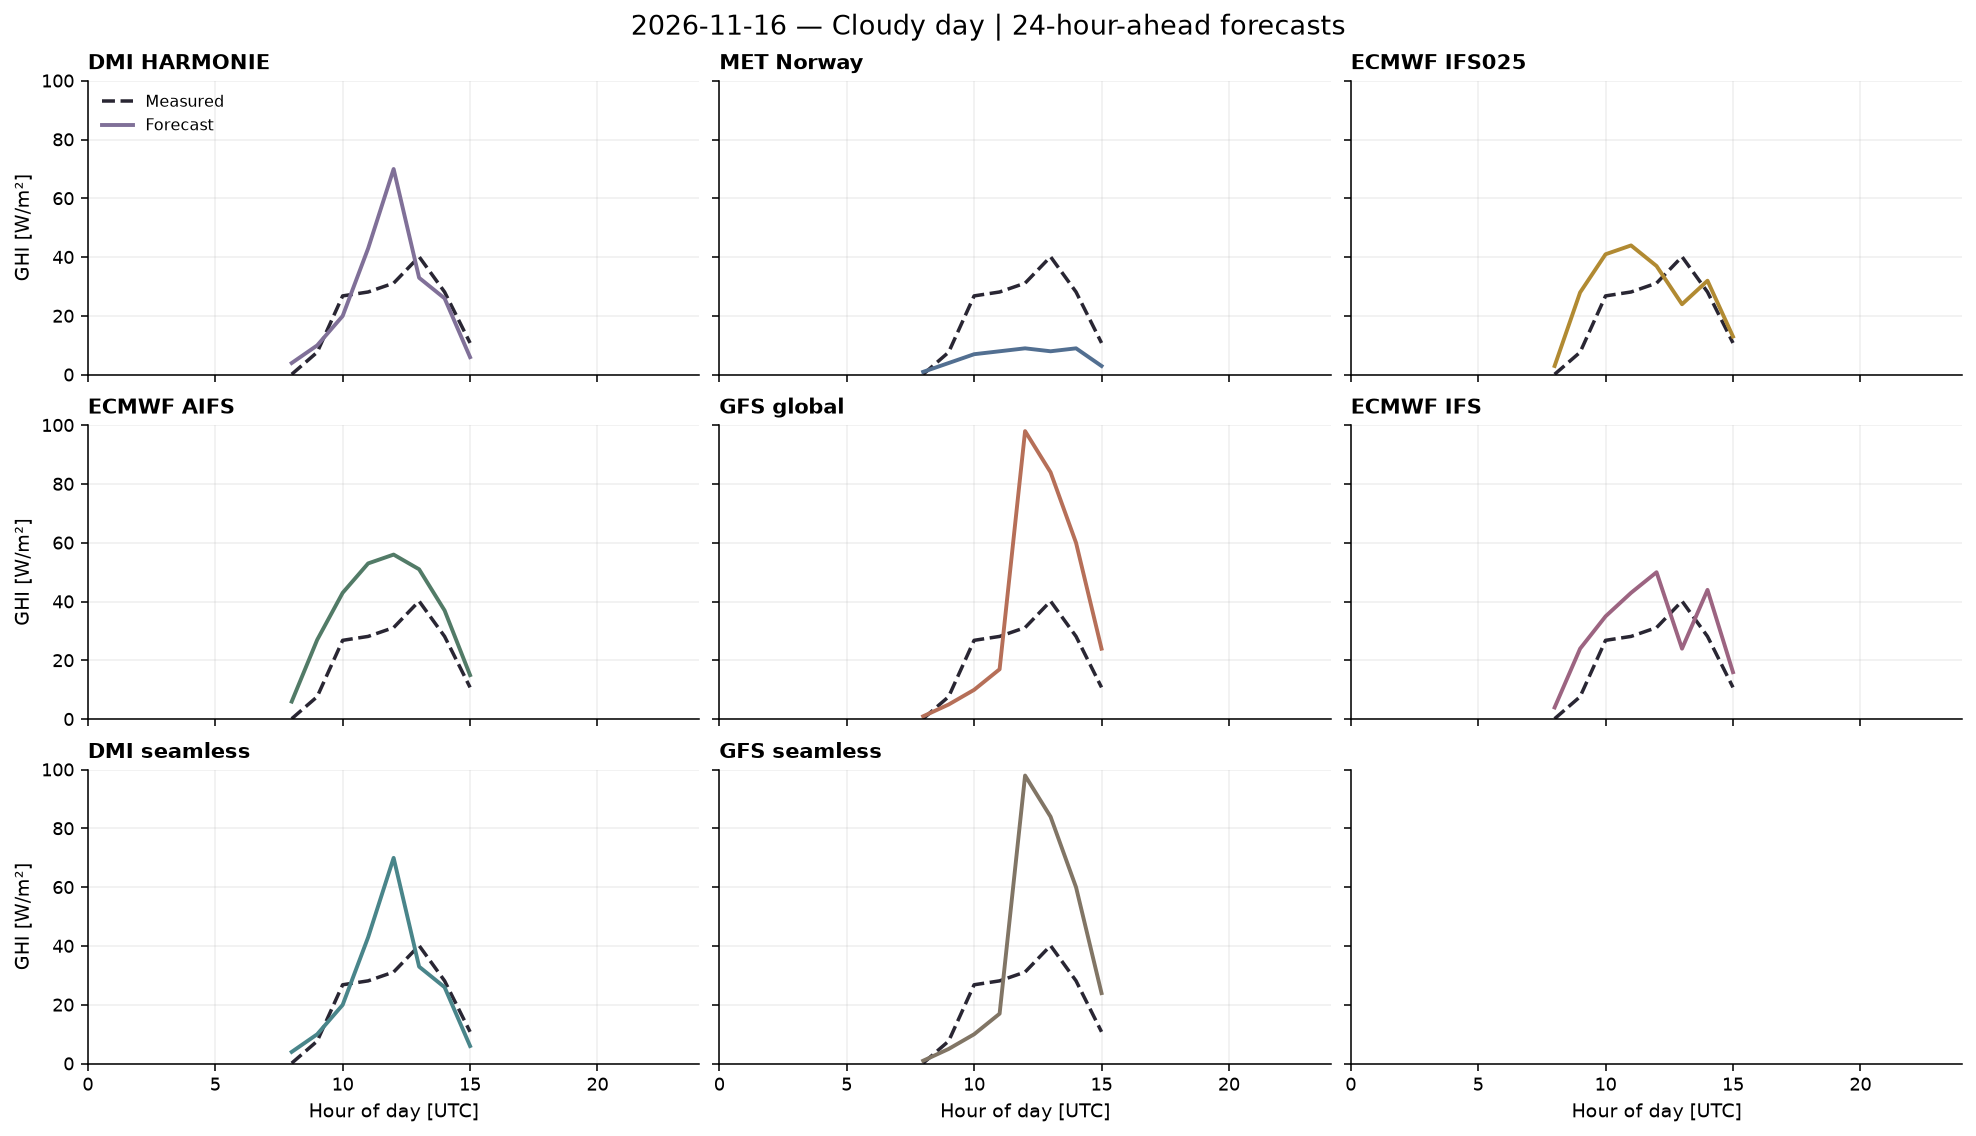

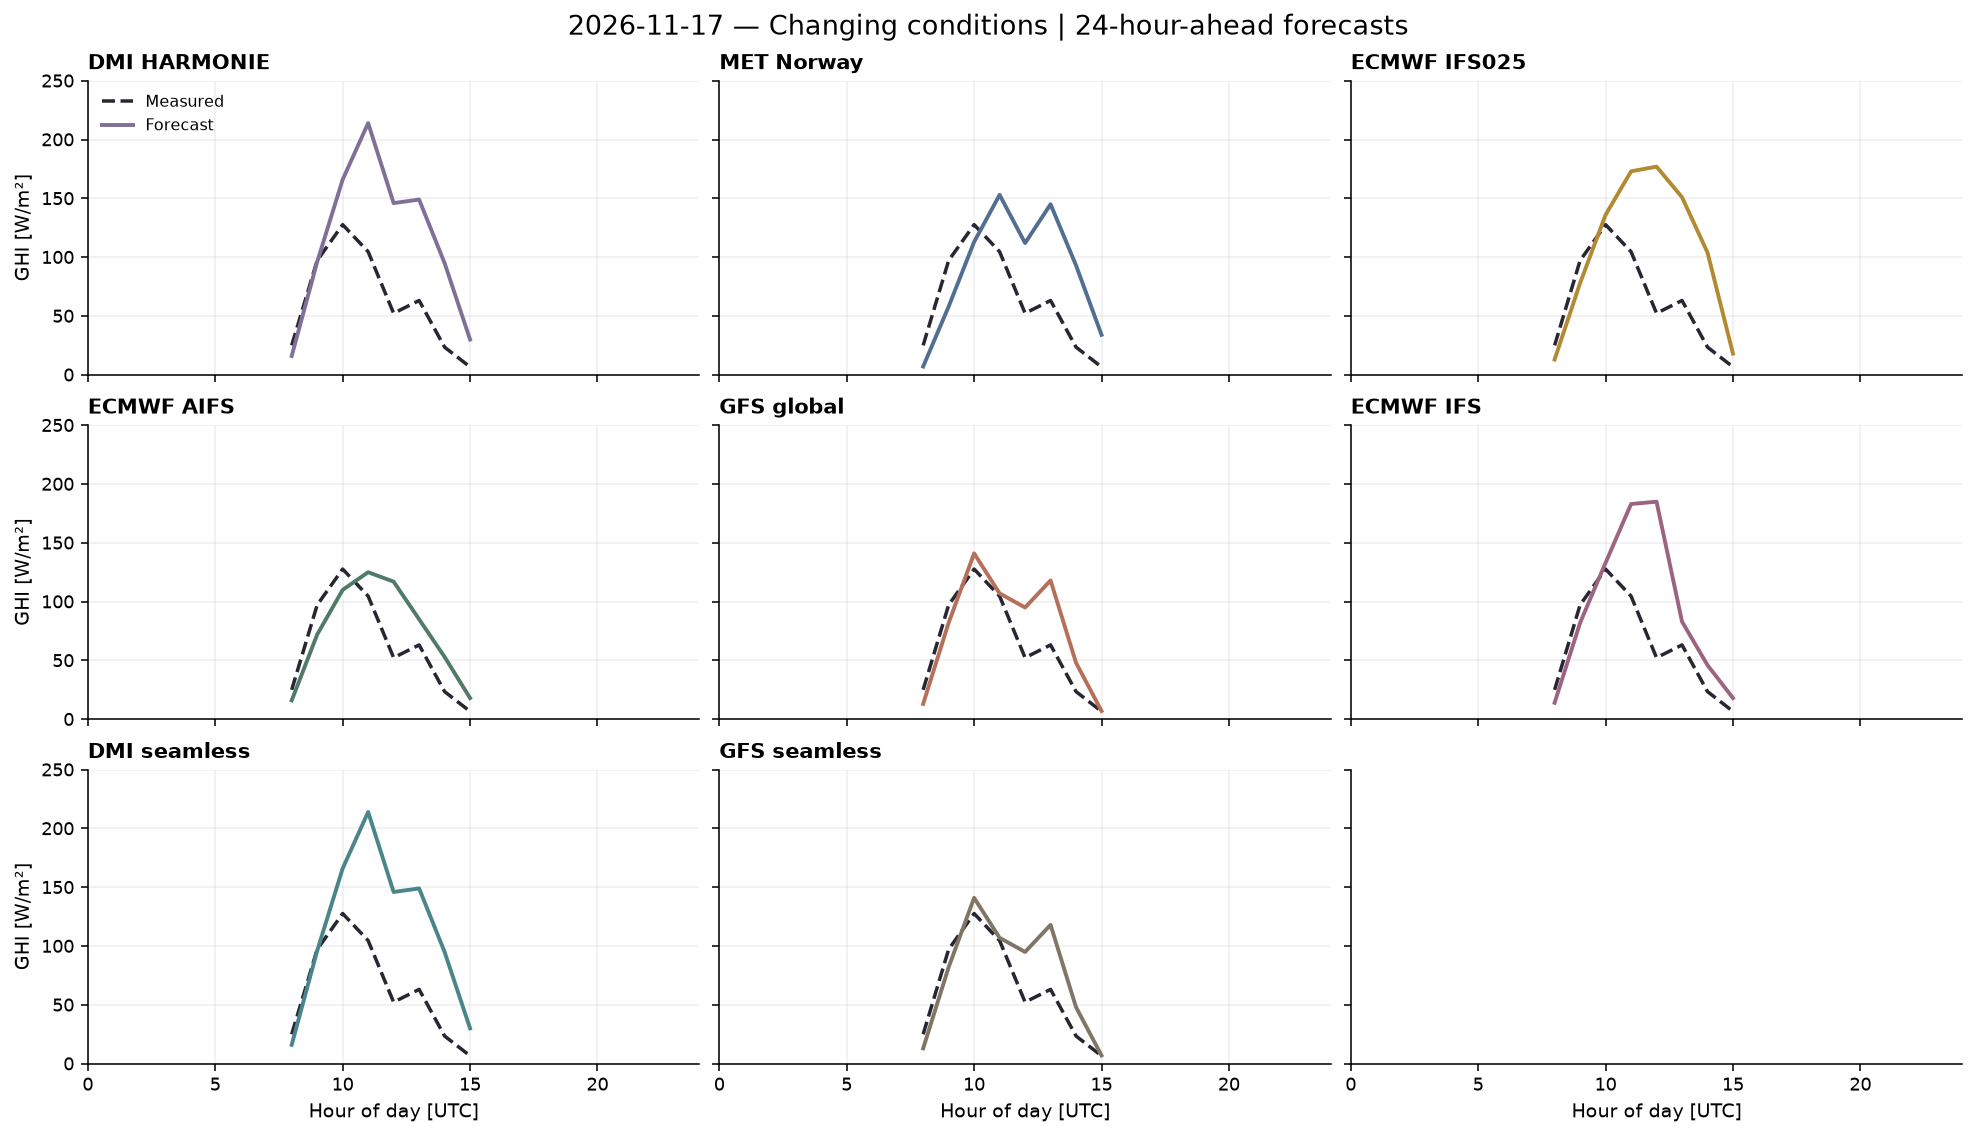

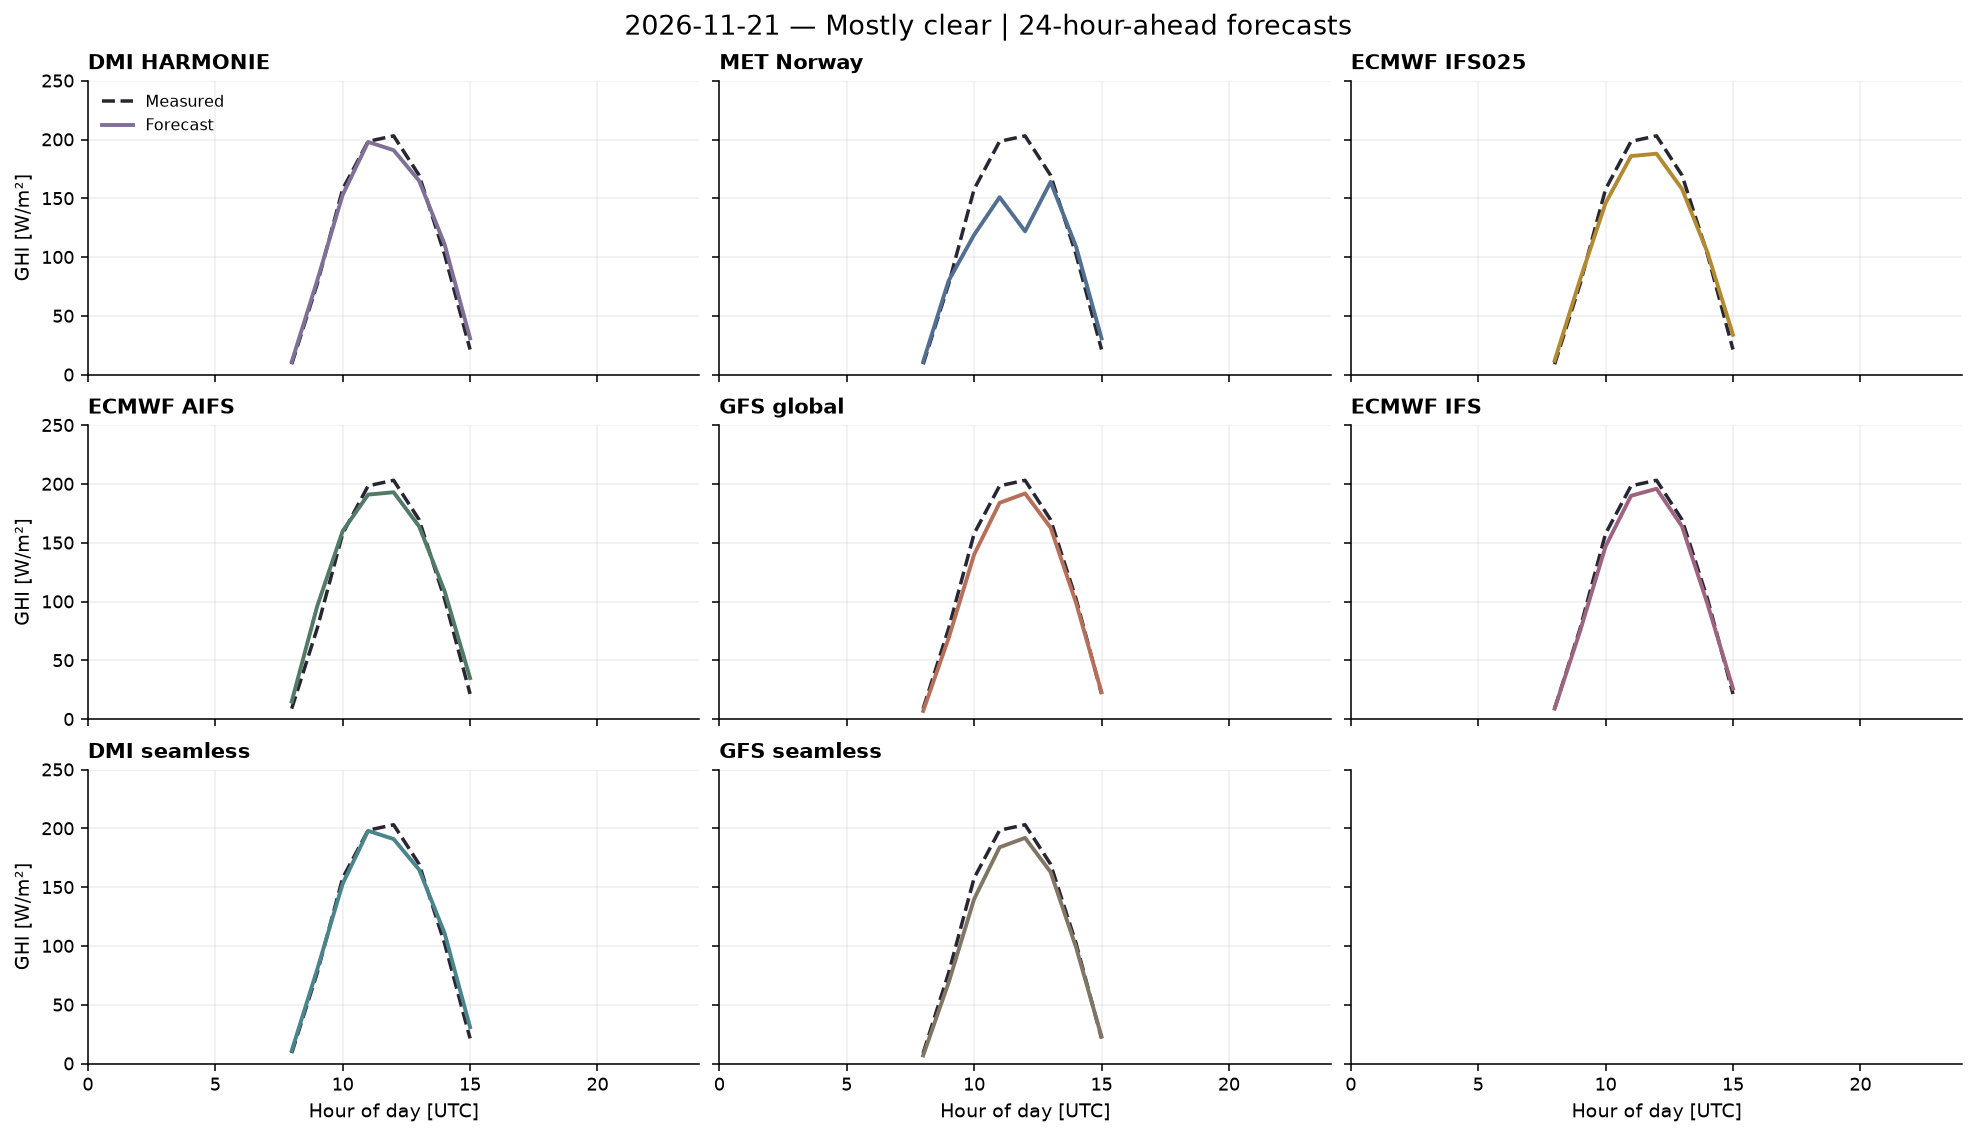

In [136]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}
lead_time = 24
measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)
model_names = list(forecast_unstacked)
model_labels = {
    "dmi_harmonie_arome_europe": "DMI HARMONIE",
    "metno_nordic": "MET Norway",
    "ecmwf_ifs025": "ECMWF IFS025",
    "ecmwf_aifs025_single": "ECMWF AIFS",
    "gfs_global": "GFS global",
    "ecmwf_ifs": "ECMWF IFS",
    "dmi_seamless": "DMI seamless",
    "gfs_seamless": "GFS seamless",
}

for date, description in profile_days.items():
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    measured_mask = (measured.index > start) & (measured.index <= end)
    measured_day = measured.loc[measured_mask].dropna()
    comparisons = {}

    for model, forecast in forecast_unstacked.items():
        if lead_time not in forecast.columns:
            continue
        forecast_mask = (forecast.index > start) & (forecast.index <= end)
        model_forecast = forecast.loc[forecast_mask, lead_time].replace(
            [np.inf, -np.inf], np.nan
        )
        comparison = pd.concat(
            [model_forecast.rename("forecast"), measured_day.rename("measured")],
            axis=1,
        ).dropna()
        if not comparison.empty:
            comparisons[model] = comparison

    if not comparisons:
        print(f"No matched data for {date} at lead time {lead_time} h.")
        continue

    max_ghi = max(
        max(data["forecast"].max(), data["measured"].max())
        for data in comparisons.values()
    )
    y_max = max(100, np.ceil(max_ghi / 50) * 50)
    fig, axes = plt.subplots(
        3, 3,
        figsize=(14, 8),
        sharex=True,
        sharey=True,
        constrained_layout=True,
    )

    for ax, model in zip(axes.flat, model_names):
        if model not in comparisons:
            ax.set_visible(False)
            continue
        data = comparisons[model]
        hour = (data.index - start).total_seconds() / 3600
        ax.plot(hour, data["measured"], color="#292633", linestyle="--", linewidth=1.8, label="Measured")
        ax.plot(hour, data["forecast"], color=colors.get(model, "#526F91"), linewidth=2, label="Forecast")
        ax.set_title(model_labels.get(model, model), loc="left", fontweight="bold")
        ax.set_xlim(0, 24)
        ax.set_ylim(0, y_max)
        ax.grid(alpha=0.2)

    axes[0, 0].legend(frameon=False, loc="upper left")
    for ax in axes[-1]:
        if ax.get_visible():
            ax.set_xlabel("Hour of day [UTC]")
    for ax in axes[:, 0]:
        if ax.get_visible():
            ax.set_ylabel("GHI [W/m²]")
    fig.suptitle(f"{date} — {description} | {lead_time}-hour-ahead forecasts", fontsize=14)
    plt.show()


### Performance on different daily profiles

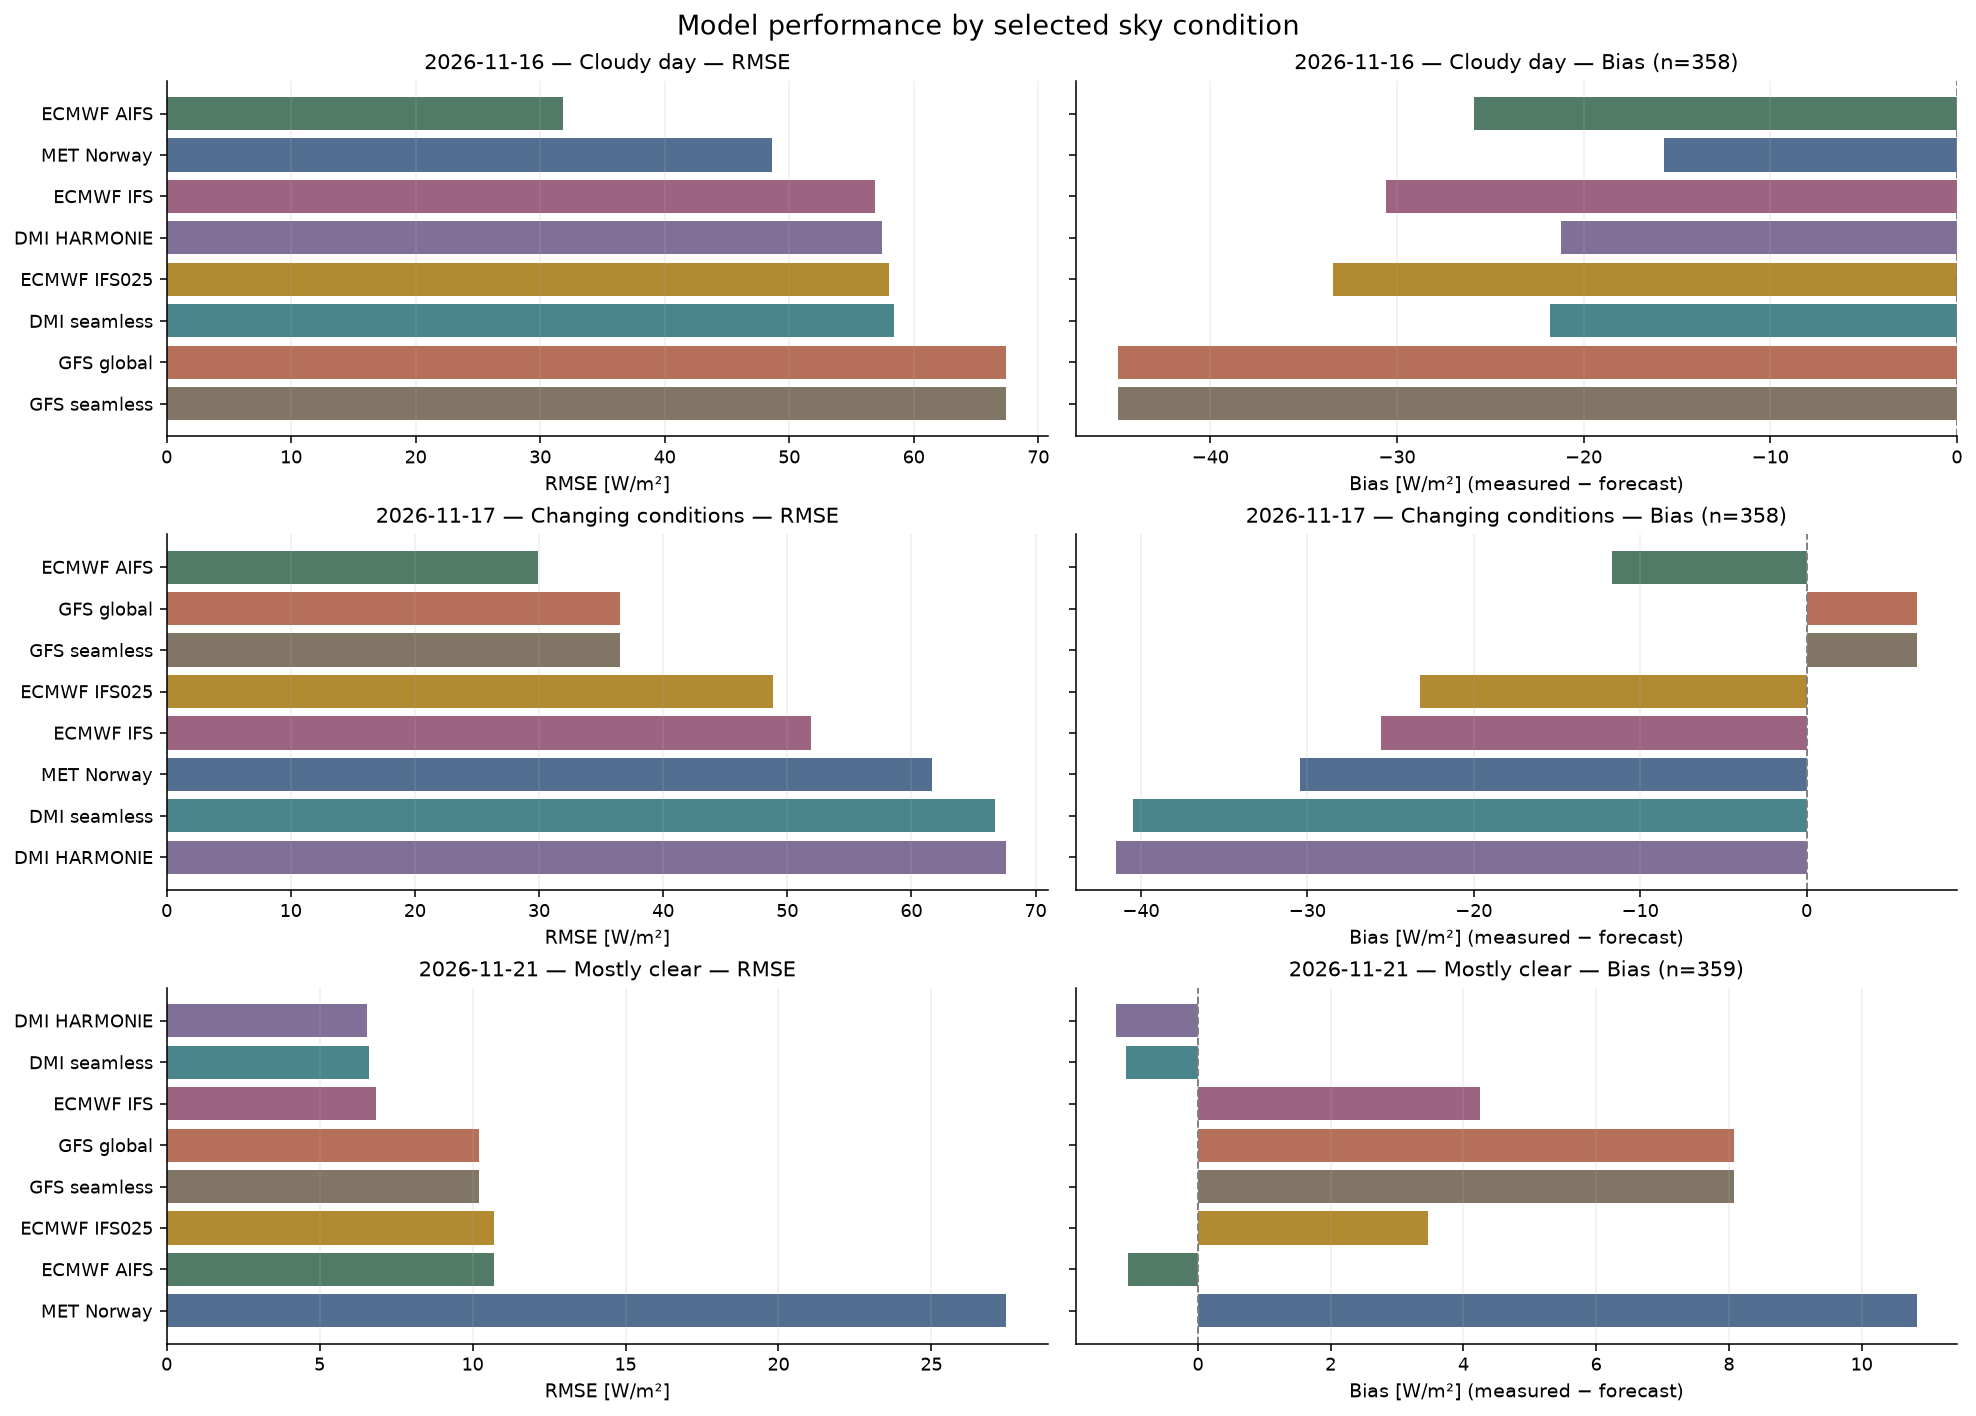

In [137]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

profile_days = {
    "2026-11-16": "Cloudy day",
    "2026-11-17": "Changing conditions",
    "2026-11-21": "Mostly clear",
}
models = list(forecast_unstacked)
measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)

# Compare all models on common lead times so their daily scores are comparable.
shared_leads = set.intersection(
    *(set(forecast.columns) for forecast in forecast_unstacked.values())
)
shared_leads = sorted(lead for lead in shared_leads if 10 <= lead <= 54)
if not shared_leads:
    raise ValueError("No common forecast lead times are available for the selected models.")

rmse_by_day = {}
bias_by_day = {}
common_counts = {}

for date, description in profile_days.items():
    start = pd.Timestamp(date, tz="UTC")
    end = start + pd.Timedelta(days=1)
    predictions = {}

    for model, forecast in forecast_unstacked.items():
        day_mask = (forecast.index > start) & (forecast.index <= end)
        subset = forecast.loc[day_mask, shared_leads].replace([np.inf, -np.inf], np.nan).copy()
        subset.index.name = "valid_time"
        subset.columns.name = "lead_time_h"
        predictions[model] = subset.stack().dropna()

    paired = pd.concat(predictions, axis=1).dropna()
    observations = measured.reindex(paired.index.get_level_values("valid_time"))
    observations.index = paired.index
    valid = observations.notna()
    paired = paired.loc[valid]
    observations = observations.loc[valid]

    errors = paired.rsub(observations, axis=0)
    label = f"{date} — {description}"
    rmse_by_day[label] = np.sqrt(errors.pow(2).mean())
    bias_by_day[label] = errors.mean()
    common_counts[label] = len(errors)

rmse_day_table = pd.DataFrame(rmse_by_day).T.reindex(columns=models)
bias_day_table = pd.DataFrame(bias_by_day).T.reindex(columns=models)

fig, axes = plt.subplots(
    len(profile_days), 2,
    figsize=(14, 10),
    sharey="row",
    constrained_layout=True,
)
for row, label in enumerate(rmse_day_table.index):
    order = rmse_day_table.loc[label].sort_values().index
    axes[row, 0].barh(
        [model_labels.get(model, model) for model in order],
        rmse_day_table.loc[label, order],
        color=[colors.get(model, "#526F91") for model in order],
    )
    axes[row, 0].invert_yaxis()
    axes[row, 0].set_title(f"{label} — RMSE")
    axes[row, 0].set_xlabel("RMSE [W/m²]")
    axes[row, 0].grid(axis="x", alpha=0.2)

    axes[row, 1].barh(
        [model_labels.get(model, model) for model in order],
        bias_day_table.loc[label, order],
        color=[colors.get(model, "#526F91") for model in order],
    )
    axes[row, 1].axvline(0, color="grey", linestyle="--", linewidth=1)
    axes[row, 1].set_title(f"{label} — Bias (n={common_counts[label]})")
    axes[row, 1].set_xlabel("Bias [W/m²] (measured − forecast)")
    axes[row, 1].grid(axis="x", alpha=0.2)

fig.suptitle("Model performance by selected sky condition", fontsize=14)
plt.show()


### Build our forecast 

In [138]:
# Define lead-time intervals to tune separately.
intervals = [(first, first + 5) for first in range(10, 106, 6)]

# Split by valid time so forecasts for the same observed hour cannot appear
# in both sets, even when they have different lead times.
measured_times = hourly_dmi.index[hourly_dmi["ghi_measured"].notna()]
forecast_times = pd.Index([])
for forecast in forecast_unstacked.values():
    forecast_times = forecast_times.union(forecast.index)

matched_times = measured_times.intersection(forecast_times).sort_values()
if len(matched_times) < 2:
    raise ValueError("Fewer than two matched valid times are available for the train/validation split.")
split_position = int(len(matched_times) * 0.70)
split_position = min(max(split_position, 1), len(matched_times) - 1)
validation_start = matched_times[split_position]

forecast_train = {
    model: forecast.loc[forecast.index < validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}
forecast_validation = {
    model: forecast.loc[forecast.index >= validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}

print(f"Training period ends before: {validation_start}")
print(f"Validation period starts:    {validation_start}")
print(f"Matched valid times: {len(matched_times)}")

# Search weights on training data, then keep a blend only when it improves
# validation RMSE over the best single model selected from training data.
weight_schedule, blend_diagnostics, weight_search = (
    fit_blend_weights_by_lead_time(
        forecast_train,
        forecast_validation,
        hourly_dmi,
        intervals=intervals,
        min_train_samples=30,
        min_validation_samples=10,
    )
)

# This schedule contains either the validated blend or a single-model fallback.
display(blend_diagnostics[[
    "interval",
    "status",
    "training_selected_single_model",
    "validation_rmse_best_single",
    "validation_rmse_blend",
    "n_validation",
]])

# Apply the accepted schedule to all available forecasts for later use.
blended_forecast = our_blend_by_lead_time(
    forecast_unstacked,
    weight_schedule,
)
blended_validation = our_blend_by_lead_time(
    forecast_validation,
    weight_schedule,
)


Training period ends before: 2026-11-19 10:00:00+00:00
Validation period starts:    2026-11-19 10:00:00+00:00
Matched valid times: 118


,interval,status,training_selected_single_model,validation_rmse_best_single,validation_rmse_blend,n_validation
0,10–15 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,26.944015,21.689040,216
1,16–21 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.625695,21.403885,216
2,22–27 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.006971,24.509374,216
3,28–33 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.031425,24.255714,216
4,34–39 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.394804,23.780965,216
5,40–45 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.870026,27.088391,216
6,46–51 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,26.510247,26.277602,216
7,52–57 h,Fallback: optimizer did not converge,ecmwf_aifs025_single,26.965561,NaN,118
8,58–63 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.237892,26.489090,216
9,64–69 h,Fallback: no validation improvement,ecmwf_aifs025_single,31.405281,35.425096,216


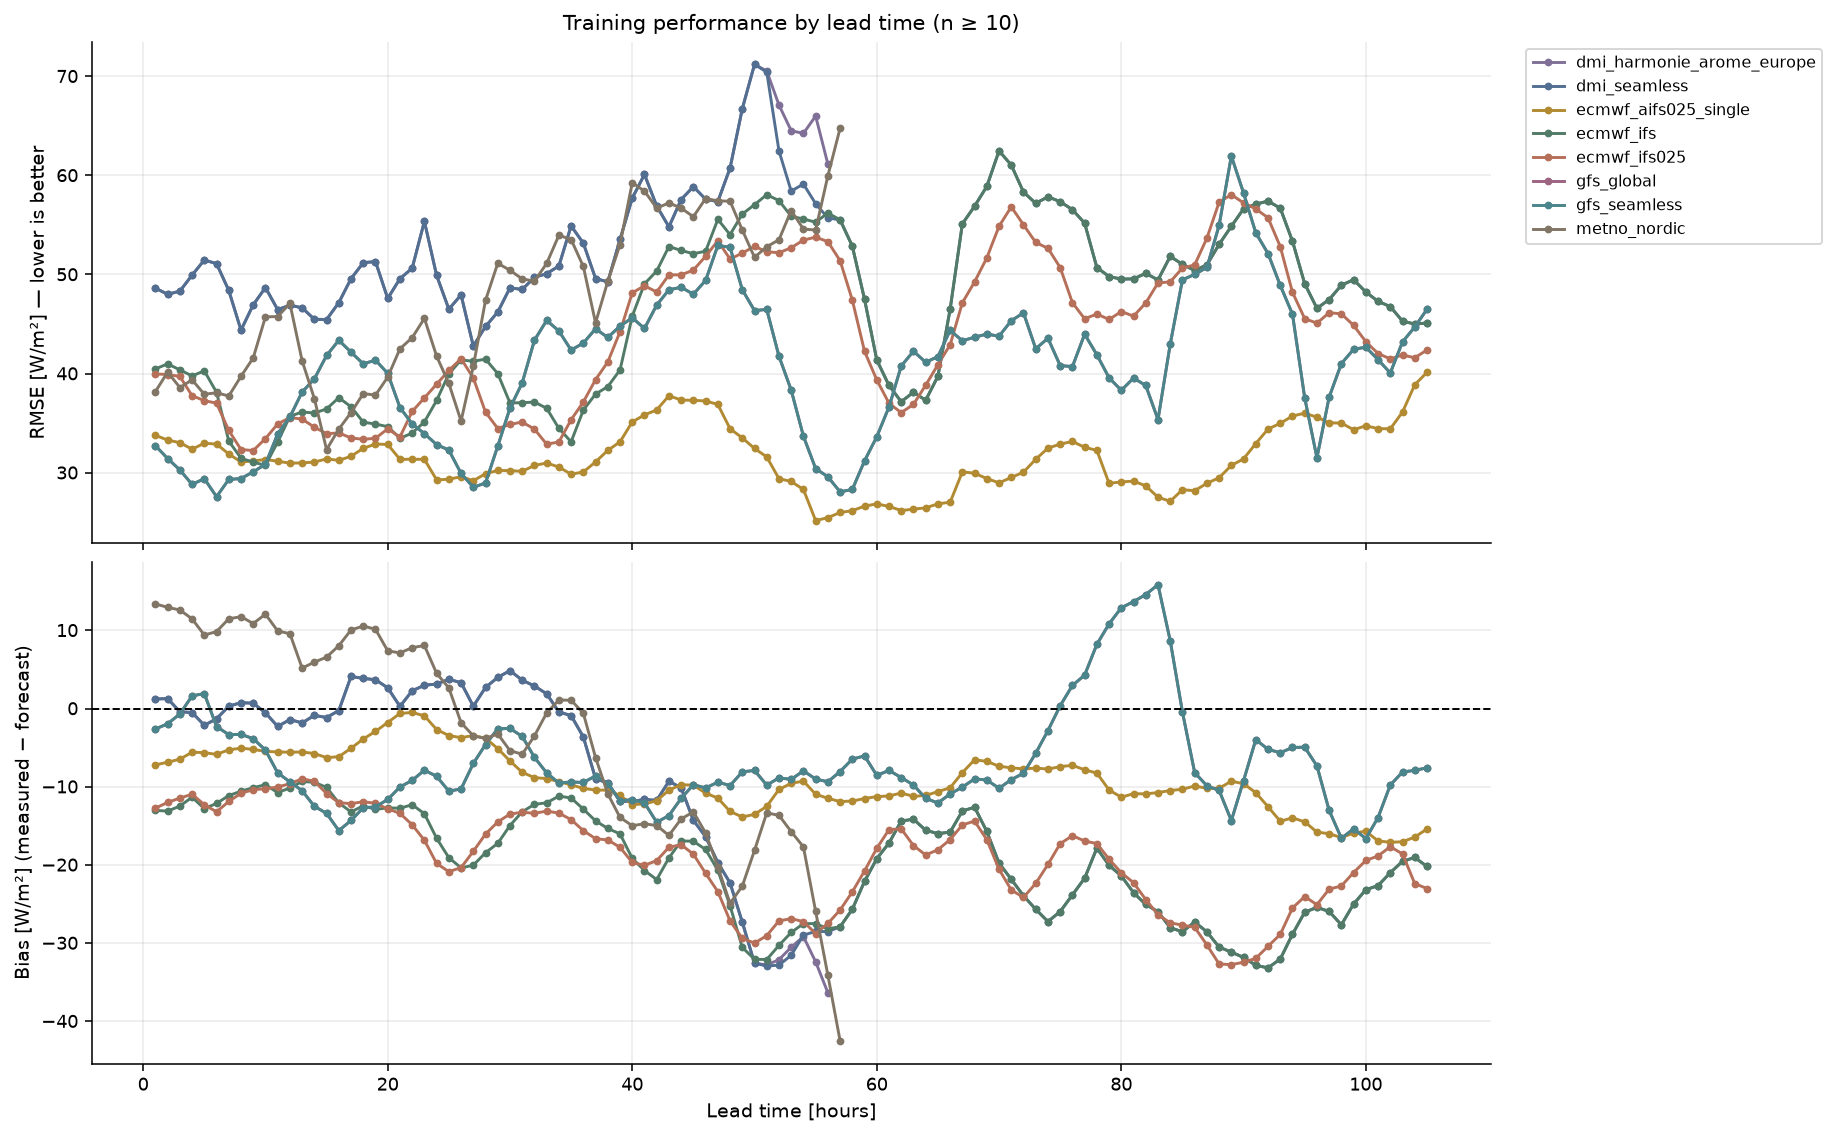

In [139]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

measured_train = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

training_scores = []

for model, forecast in forecast_train.items():
    for lead in forecast.columns:
        try:
            lead_h = int(lead)
        except (TypeError, ValueError):
            continue

        if not 1 <= lead_h <= 105:
            continue

        prediction = forecast[lead].replace([np.inf, -np.inf], np.nan)
        observation = measured_train.reindex(prediction.index)

        pairs = pd.concat(
            [observation.rename("measured"), prediction.rename("forecast")],
            axis=1,
        ).dropna()

        if pairs.empty:
            continue

        error = pairs["measured"] - pairs["forecast"]

        training_scores.append({
            "model": model,
            "lead_time_h": lead_h,
            "n": len(pairs),
            "rmse": np.sqrt(np.mean(error**2)),
            "bias": error.mean(),
        })

training_scores = pd.DataFrame(training_scores)

# Skjul lead times med få observationer.
min_samples = 10
training_scores.loc[
    training_scores["n"] < min_samples, ["rmse", "bias"]
] = np.nan

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True,
    constrained_layout=True,
)

for model, group in training_scores.groupby("model"):
    group = group.sort_values("lead_time_h")
    axes[0].plot(group["lead_time_h"], group["rmse"], marker=".", label=model)
    axes[1].plot(group["lead_time_h"], group["bias"], marker=".", label=model)

axes[0].set_title(f"Training performance by lead time (n ≥ {min_samples})")
axes[0].set_ylabel("RMSE [W/m²] — lower is better")
axes[0].grid(alpha=0.25)
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

axes[1].axhline(0, color="black", linewidth=1, linestyle="--")
axes[1].set_ylabel("Bias [W/m²] (measured − forecast)")
axes[1].set_xlabel("Lead time [hours]")
axes[1].grid(alpha=0.25)

plt.show()

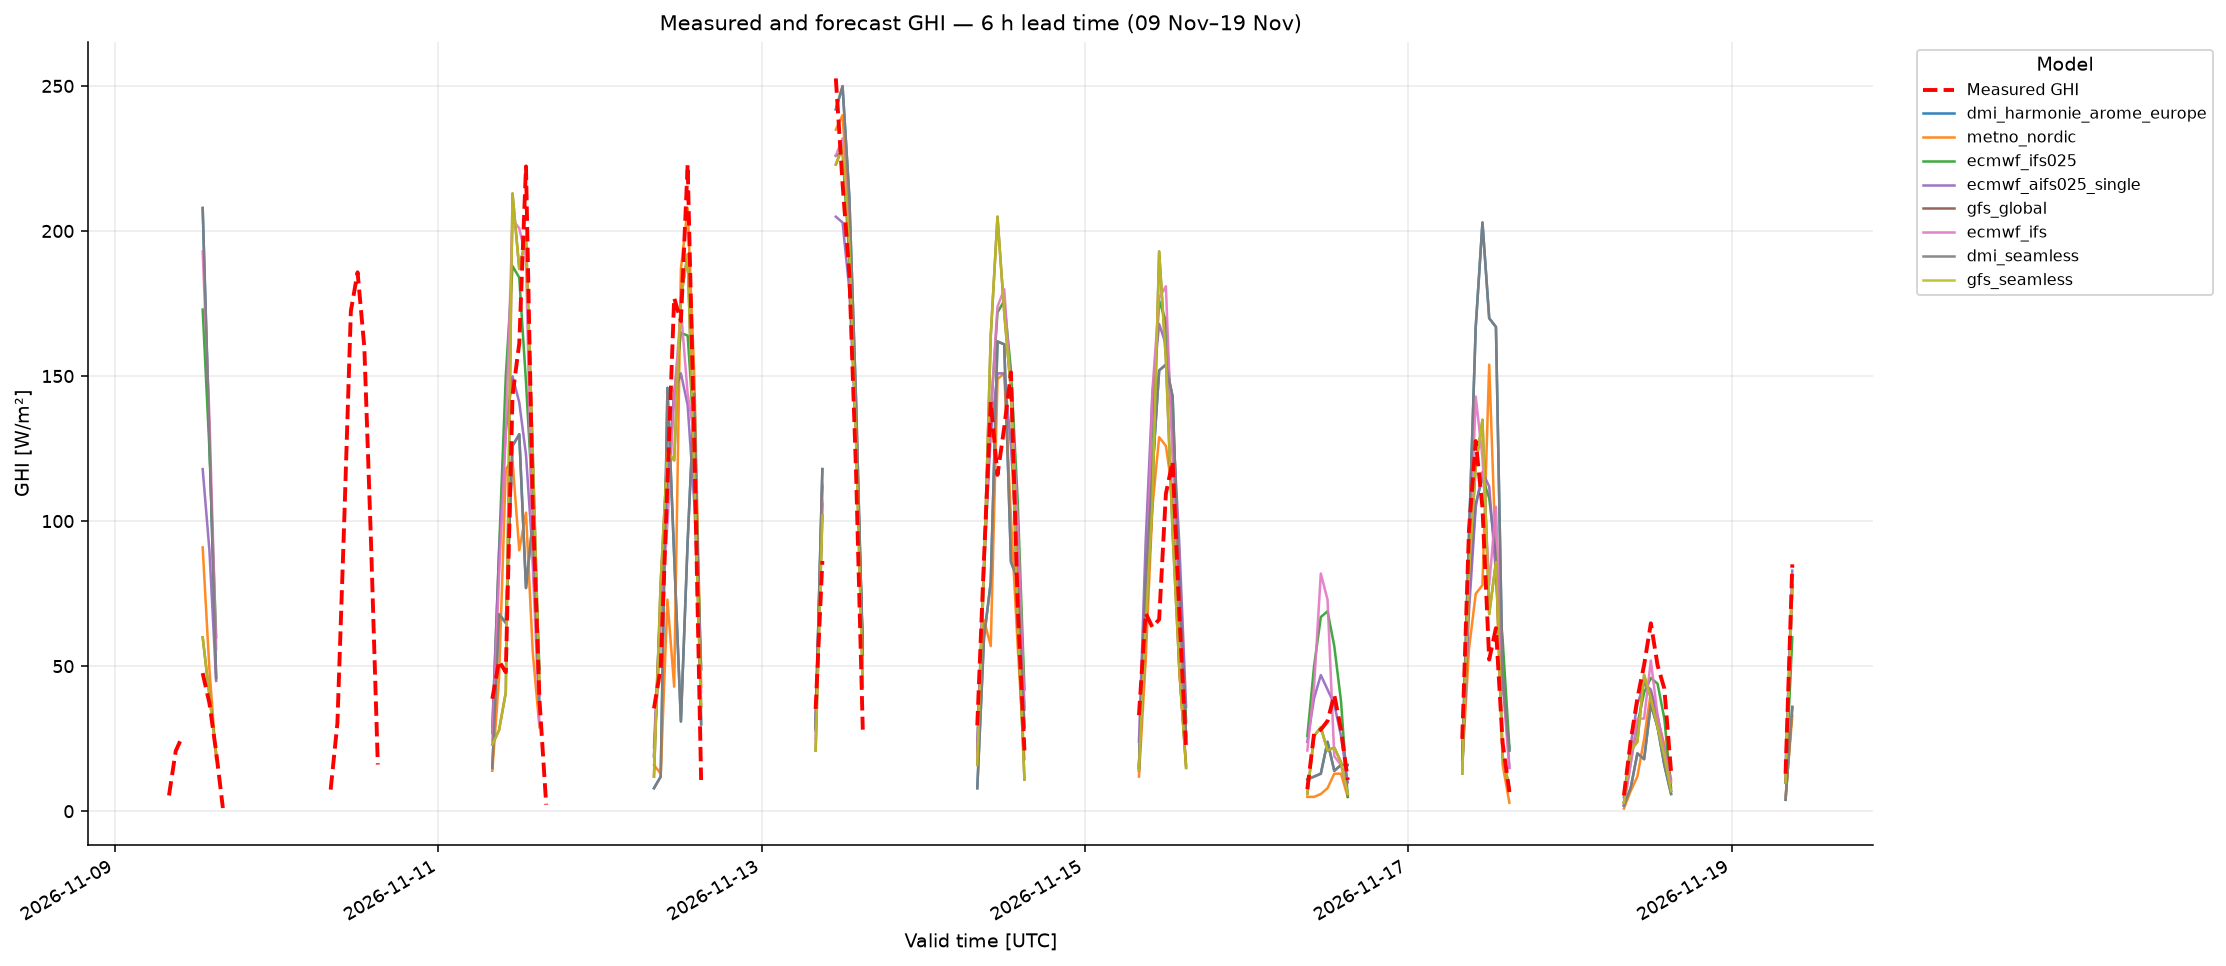

In [146]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_lead = 6
start_date = pd.Timestamp("2026-11-09", tz="UTC")
end_date = pd.Timestamp("2026-11-28", tz="UTC")  # Eksklusiv slutdato

measured = hourly_dmi["ghi_measured"].replace([np.inf, -np.inf], np.nan)

# Find den periode, hvor træningsforecastene faktisk findes.
available_times = pd.Index([])
for forecast in forecast_train.values():
    available_times = available_times.union(forecast.index)

if available_times.empty:
    raise ValueError("No training forecast timestamps are available.")

plot_start = max(start_date, available_times.min()).floor("h")
plot_end = min(end_date, available_times.max() + pd.Timedelta(hours=1))

# Indsæt alle timer, også dem der mangler i data.
plot_index = pd.date_range(
    start=plot_start,
    end=plot_end,
    freq="h",
    inclusive="left",
)

measured_plot = measured.reindex(plot_index)

# Brug målt GHI til at identificere dagtimer; nat bliver NaN, så linjerne brydes.
daylight_mask = measured_plot > 1

fig, ax = plt.subplots(figsize=(16, 7))

ax.plot(
    plot_index,
    measured_plot.where(daylight_mask),
    color="red",
    linestyle="--",
    linewidth=2,
    label="Measured GHI",
    zorder=10,
)

model_colors = [
    "#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22",
]

for i, (model, forecast) in enumerate(forecast_train.items()):
    if plot_lead not in forecast.columns:
        continue

    prediction = (
        forecast[plot_lead]
        .replace([np.inf, -np.inf], np.nan)
        .reindex(plot_index)
    )

    ax.plot(
        plot_index,
        prediction.where(daylight_mask),
        color=model_colors[i % len(model_colors)],
        linewidth=1.3,
        alpha=0.9,
        label=model,
    )

ax.set_title(
    f"Measured and forecast GHI — {plot_lead} h lead time "
    f"({plot_start:%d Nov}–{(plot_end - pd.Timedelta(hours=1)):%d Nov})"
)
ax.set_xlabel("Valid time [UTC]")
ax.set_ylabel("GHI [W/m²]")
ax.grid(alpha=0.25)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# Brug træningsdata. Hvert punkt er ét forecast ved én lead time.
models = forecast_train
measured = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

model_pairs = {}

for model, df in models.items():
    rows = []

    for lead in df.columns:
        try:
            lead_h = int(lead)
        except (TypeError, ValueError):
            continue

        forecast = df[lead].replace([np.inf, -np.inf], np.nan)
        observation = measured.reindex(forecast.index)

        pairs = pd.concat(
            [
                forecast.rename("forecast"),
                observation.rename("measured"),
            ],
            axis=1,
        ).dropna()

        if not pairs.empty:
            pairs["lead_time_h"] = lead_h
            rows.append(pairs)

    if rows:
        model_pairs[model] = pd.concat(rows)

if not model_pairs:
    raise ValueError("No matched forecast-measurement pairs in the training data.")

# Brug samme aksegrænser i alle paneler.
all_values = np.concatenate([
    np.concatenate([pairs["forecast"].to_numpy(), pairs["measured"].to_numpy()])
    for pairs in model_pairs.values()
])
lower = min(0, np.nanmin(all_values))
upper = max(1, np.nanmax(all_values))
padding = (upper - lower) * 0.05
limits = (lower - padding, upper + padding)

all_leads = np.concatenate([
    pairs["lead_time_h"].to_numpy()
    for pairs in model_pairs.values()
])
norm = Normalize(vmin=all_leads.min(), vmax=all_leads.max())
cmap = plt.get_cmap("viridis")

ncols = 2
nrows = int(np.ceil(len(model_pairs) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 5 * nrows),
    constrained_layout=True,
)
axes = np.atleast_1d(axes).ravel()

for ax, (model, pairs) in zip(axes, model_pairs.items()):
    residual = pairs["forecast"] - pairs["measured"]
    rmse = np.sqrt(np.mean(residual**2))
    bias = residual.mean()

    points = ax.scatter(
        pairs["forecast"],
        pairs["measured"],
        c=pairs["lead_time_h"],
        cmap=cmap,
        norm=norm,
        alpha=0.55,
        s=18,
        edgecolors="none",
    )

    ax.plot(
        limits,
        limits,
        color="red",
        linestyle="--",
        linewidth=1,
        label="Perfect forecast",
    )

    ax.set(
        xlim=limits,
        ylim=limits,
        xlabel="Forecasted GHI [W/m²]",
        ylabel="Measured GHI [W/m²]",
        title=(
            f"{model}\n"
            f"RMSE = {rmse:.1f}, bias = {bias:.1f} W/m² "
            f"(forecast − measured)"
        ),
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)

for ax in axes[len(model_pairs):]:
    ax.set_visible(False)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=axes[:len(model_pairs)].tolist(),
    shrink=0.85,
)
colorbar.set_label("Lead time [hours]")

fig.suptitle(
    "Forecasted versus measured GHI on training data — all available lead times",
    fontsize=15,
)
plt.show()

,interval,status,training_selected_single_model,validation_rmse_best_single,validation_rmse_blend,validation_rmse_final,n_validation
0,10–15 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,26.944015,21.689040,21.689040,216
1,16–21 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.625695,21.403885,21.403885,216
2,22–27 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.006971,24.509374,24.509374,216
3,28–33 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.031425,24.255714,24.255714,216
4,34–39 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.394804,23.780965,23.780965,216
5,40–45 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,28.870026,27.088391,27.088391,216
6,46–51 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,26.510247,26.277602,26.277602,216
7,52–57 h,Fallback: optimizer did not converge,ecmwf_aifs025_single,26.965561,NaN,26.965561,118
8,58–63 h,Accepted: lower validation RMSE,ecmwf_aifs025_single,27.237892,26.489090,26.489090,216
9,64–69 h,Fallback: no validation improvement,ecmwf_aifs025_single,31.405281,35.425096,31.405281,216


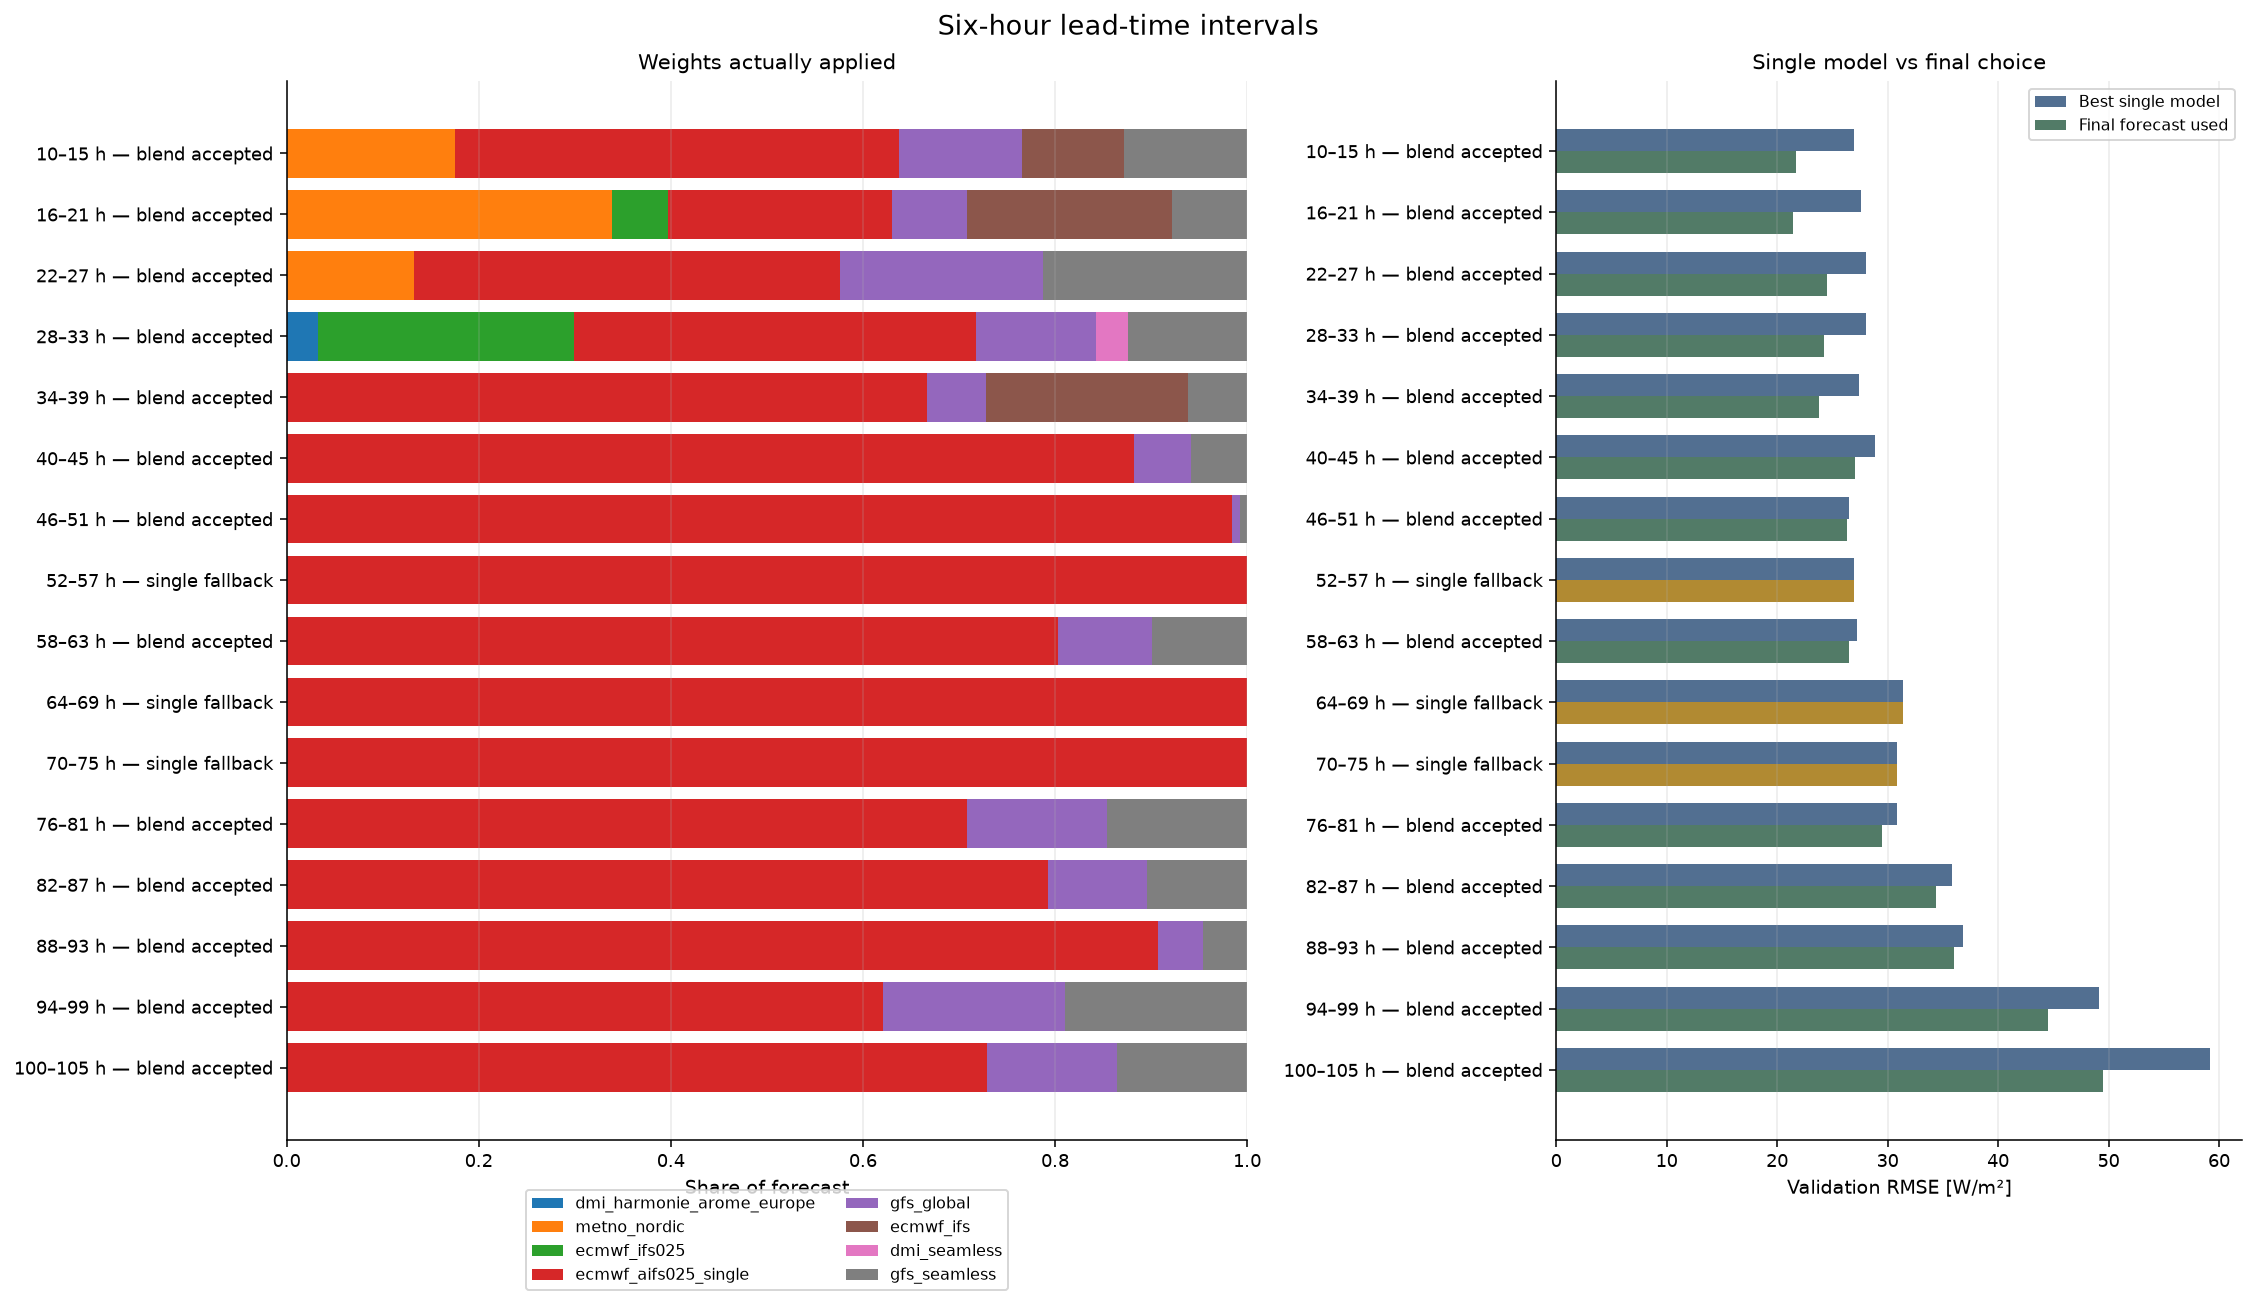

In [141]:
# Simple summary: weights actually used and validation RMSE comparison.
interval_labels = [f"{first}–{last} h" for first, last, _ in weight_schedule]
weight_rows = [weights for _, _, weights in weight_schedule]
weight_table = pd.DataFrame(weight_rows, index=interval_labels).fillna(0)
weight_table = weight_table.reindex(columns=list(forecast_unstacked), fill_value=0)

summary = blend_diagnostics.copy()
summary["validation_rmse_final"] = np.where(
    summary["accepted"],
    summary["validation_rmse_blend"],
    summary["validation_rmse_best_single"],
)
summary_labels = [
    f"{row.interval} — {'blend accepted' if row.accepted else 'single fallback'}"
    for row in summary.itertuples()
]

display(summary[[
    "interval",
    "status",
    "training_selected_single_model",
    "validation_rmse_best_single",
    "validation_rmse_blend",
    "validation_rmse_final",
    "n_validation",
]])

fig_height = max(7, 0.45 * len(interval_labels) + 2)
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, fig_height),
    gridspec_kw={"width_ratios": [1.4, 1]},
    constrained_layout=True,
)
y = np.arange(len(interval_labels))

# Each row sums to one and shows the model shares used in that interval.
ax = axes[0]
left = np.zeros(len(weight_table))
palette = plt.get_cmap("tab10")
for i, model in enumerate(weight_table.columns):
    values = weight_table[model].to_numpy()
    if np.any(values > 0.005):
        ax.barh(
            y,
            values,
            left=left,
            label=model,
            color=palette(i % 10),
        )
        left += values
ax.set_yticks(y)
ax.set_yticklabels(summary_labels)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of forecast")
ax.set_title("Weights actually applied")
ax.grid(axis="x", alpha=0.25)
ax.legend(bbox_to_anchor=(0.5, -0.04), loc="upper center", ncol=2, fontsize=8)

# Lower validation RMSE is better. On fallback intervals the two bars are equal.
ax = axes[1]
bar_height = 0.36
ax.barh(
    y - bar_height / 2,
    summary["validation_rmse_best_single"],
    height=bar_height,
    label="Best single model",
    color="#526F91",
)
ax.barh(
    y + bar_height / 2,
    summary["validation_rmse_final"],
    height=bar_height,
    label="Final forecast used",
    color=["#527B67" if accepted else "#B18A32" for accepted in summary["accepted"]],
)
ax.set_yticks(y)
ax.set_yticklabels(summary_labels)
ax.invert_yaxis()
ax.set_xlabel("Validation RMSE [W/m²]")
ax.set_title("Single model vs final choice")
ax.grid(axis="x", alpha=0.25)
ax.legend(fontsize=8)

fig.suptitle("Six-hour lead-time intervals", fontsize=14)
plt.show()


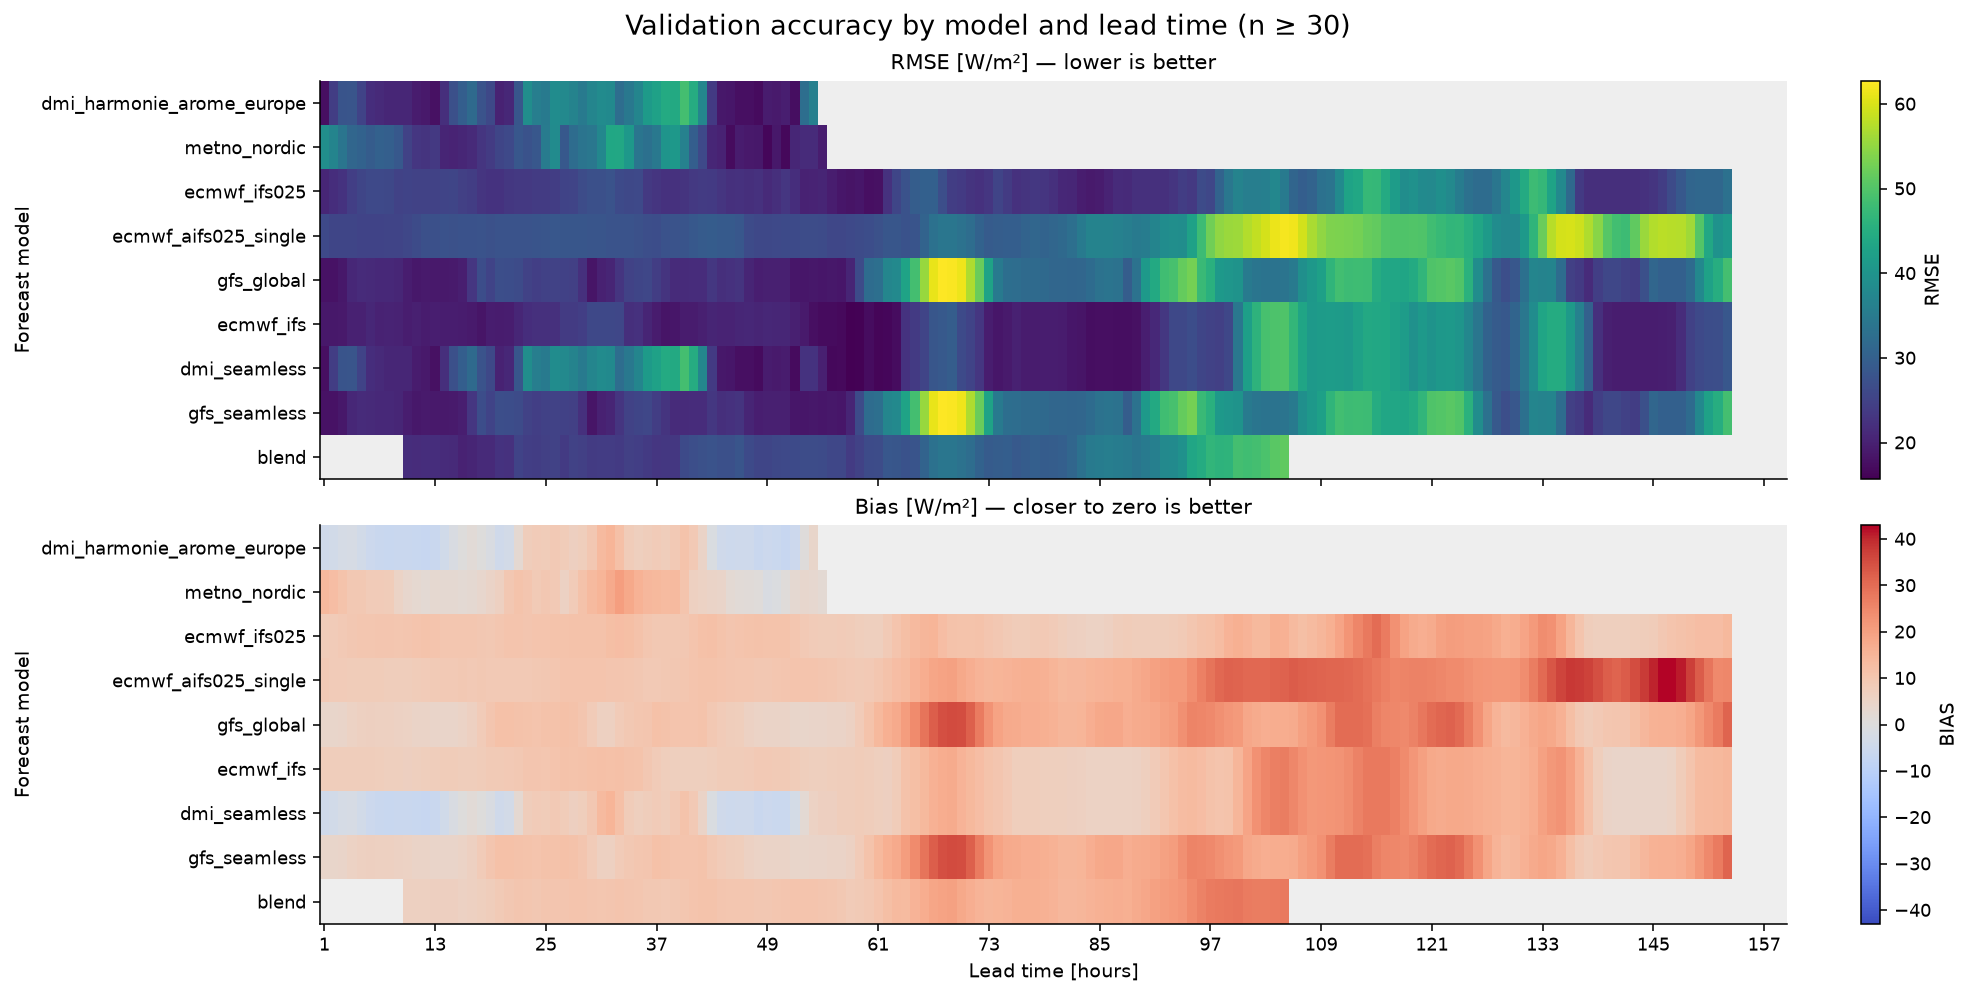

In [142]:
# Calculate validation metrics here so this cell can run independently.
validation_comparison = {
    **forecast_validation,
    "blend": blended_validation,
}
validation_scores = calculate_forecast_metrics(
    validation_comparison,
    hourly_dmi,
)

# Compare validation RMSE and bias for all models with heatmaps.
# Cells with fewer than 30 matched forecast-measurement pairs are hidden.
min_samples_for_plot = 30
scores_for_heatmap = validation_scores.copy()
scores_for_heatmap.loc[
    scores_for_heatmap["n"] < min_samples_for_plot,
    ["rmse", "bias"],
] = np.nan

model_order = list(dict.fromkeys(scores_for_heatmap["model"]))
lead_order = sorted(scores_for_heatmap["lead_time_h"].unique())

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 7),
    sharex=True,
    constrained_layout=True,
)

for ax, metric, title, cmap_name in [
    (axes[0], "rmse", "RMSE [W/m²] — lower is better", "viridis"),
    (axes[1], "bias", "Bias [W/m²] — closer to zero is better", "coolwarm"),
]:
    table = scores_for_heatmap.pivot(
        index="model",
        columns="lead_time_h",
        values=metric,
    ).reindex(index=model_order, columns=lead_order)
    values = table.to_numpy(dtype=float)
    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad("#eeeeee")

    if metric == "bias":
        finite_values = np.abs(values[np.isfinite(values)])
        limit = finite_values.max() if len(finite_values) else 1
        limit = max(limit, 1)
        image = ax.imshow(
            values,
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
            norm=plt.Normalize(vmin=-limit, vmax=limit),
        )
    else:
        image = ax.imshow(
            values,
            aspect="auto",
            interpolation="nearest",
            cmap=cmap,
        )

    ax.set_yticks(np.arange(len(model_order)))
    ax.set_yticklabels(model_order)
    ax.set_ylabel("Forecast model")
    ax.set_title(title)
    fig.colorbar(image, ax=ax, label=metric.upper())

# Label every 12 hours to keep the horizon axis readable.
tick_positions = np.arange(0, len(lead_order), 12)
axes[-1].set_xticks(tick_positions)
axes[-1].set_xticklabels([f"{lead_order[i]:g}" for i in tick_positions])
axes[-1].set_xlabel("Lead time [hours]")
fig.suptitle(
    f"Validation accuracy by model and lead time (n ≥ {min_samples_for_plot})",
    fontsize=14,
)
plt.show()


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path

# Perioden, der mindst skal afleveres, i UTC.
target_times = pd.date_range(
    "2026-11-28 01:00",
    "2026-11-30 23:00",
    freq="h",
    tz="UTC",
)

# Hent DTU-prognoser fra de seneste tilgængelige prognosekørsler.
# Den tomme måleserie undgår at koble DMI-målinger til DTU-prognoserne.
empty_measurements = pd.DataFrame(
    {"ghi_measured": pd.Series(dtype=float)},
    index=pd.DatetimeIndex([], tz="UTC", name="valid_time"),
)

dtu_forecast_data = get_forecast_data(
    empty_measurements,
    station="dtu",
    start="2026-11-26 00:00",
    end="2026-11-27 13:00",
    models=list(forecast_unstacked),
)

# Find modeller, der faktisk har en positiv vægt i mindst ét interval.
required_models = sorted({
    model
    for _, _, weights in weight_schedule
    for model, weight in weights.items()
    if weight > 0
})

# Find fælles prognosekørsler for alle modeller, der skal bruges i blendet.
issue_time_sets = []
for model in required_models:
    model_data = dtu_forecast_data[model]
    if model_data.empty:
        raise ValueError(f"DTU forecast data is empty for model: {model}")

    issue_time_sets.append(
        set(pd.to_datetime(model_data["issue_time"], utc=True).unique())
    )

common_issue_times = set.intersection(*issue_time_sets)

# Begræns kandidaterne til issue times, hvor alle mål-timer ligger
# inden for lead-time intervallerne i den validerede vægtplan.
min_lead = min(first for first, _, _ in weight_schedule)
max_lead = max(last for _, last, _ in weight_schedule)

earliest_issue = target_times[-1] - pd.Timedelta(hours=max_lead)
latest_issue = target_times[0] - pd.Timedelta(hours=min_lead)

candidate_issue_times = sorted(
    (
        issue_time
        for issue_time in common_issue_times
        if earliest_issue <= issue_time <= latest_issue
    ),
    reverse=True,
)

selected_issue_time = None
selected_blend = None
selected_values = None

# Prøv den nyeste fælles kørsel først. Behold den kun, hvis blendet
# har en forecastværdi for hver eneste krævet time.
for issue_time in candidate_issue_times:
    leads = {
        valid_time: int(
            round((valid_time - issue_time) / pd.Timedelta(hours=1))
        )
        for valid_time in target_times
    }

    if not all(
        any(first <= lead <= last for first, last, _ in weight_schedule)
        for lead in leads.values()
    ):
        continue

    forecasts_for_issue = {}

    for model in required_models:
        model_data = dtu_forecast_data[model].copy()
        model_data["issue_time"] = pd.to_datetime(
            model_data["issue_time"], utc=True
        )
        issue_data = model_data.loc[model_data["issue_time"] == issue_time]

        forecasts_for_issue[model] = issue_data.pivot_table(
            index="valid_time",
            columns="lead_time_h",
            values="ghi_forecast",
            aggfunc="first",
        )

    blended_for_issue = our_blend_by_lead_time(
        forecasts_for_issue,
        weight_schedule,
    )

    values = []
    for valid_time, lead in leads.items():
        if valid_time not in blended_for_issue.index or lead not in blended_for_issue.columns:
            values.append(np.nan)
        else:
            values.append(blended_for_issue.at[valid_time, lead])

    values = pd.Series(values, index=target_times, dtype=float)

    if values.notna().all():
        selected_issue_time = issue_time
        selected_blend = blended_for_issue
        selected_values = values
        break

if selected_issue_time is None:
    raise ValueError(
        "No common DTU forecast run covers every required hour using the "
        "validated lead-time weights. Check whether newer DTU forecast files "
        "are available, then rerun this cell."
    )

# Create and save the submission file.
submission = pd.DataFrame({
    "valid_time": target_times,
    "ghi_forecast": selected_values.to_numpy(),
})

assert len(submission) == len(target_times)
assert submission["ghi_forecast"].notna().all()

output_file = Path(
    "dtu_blended_forecast_2026-11-28_to_2026-11-30.csv"
)
submission.to_csv(output_file, index=False)

print(f"Selected DTU forecast issue time: {selected_issue_time}")
print(f"Forecast hours: {len(submission)}")
print(f"Saved forecast file: {output_file.resolve()}")
display(submission.head())
display(submission.tail())
``` Denne vægtplan er lært på DMI-station 06019 og overført til DTU-dataene. Hvis projektbeskrivelsen kræver bestemte CSV-kolonnenavne, skal de tilpasses i `submission`.

In [149]:
import numpy as np
import pandas as pd
from pathlib import Path

# Perioden, der skal afleveres, i UTC.
target_times = pd.date_range(
    start="2026-11-28 01:00",
    end="2026-11-30 23:00",
    freq="h",
    tz="UTC",
)

# Hent de seneste DTU-prognoser.
# Målinger er ikke nødvendige for fremtidige forecasttider.
empty_measurements = pd.DataFrame(
    {"ghi_measured": pd.Series(dtype=float)},
    index=pd.DatetimeIndex([], tz="UTC", name="valid_time"),
)

dtu_forecast_data = get_forecast_data(
    empty_measurements,
    station="dtu",
    start="2026-11-26 00:00",
    end="2026-11-27 13:00",
    models=list(forecast_unstacked),
)

# Find alle modeller, der har en positiv vægt i mindst ét interval.
required_models = sorted({
    model
    for _, _, weights in weight_schedule
    for model, weight in weights.items()
    if weight > 0
})

# Find issue times, som er tilgængelige for alle modeller med positiv vægt.
issue_time_sets = []

for model in required_models:
    model_data = dtu_forecast_data[model]

    if model_data.empty:
        raise ValueError(f"Der blev ikke hentet DTU-data for modellen {model}.")

    model_issue_times = set(
        pd.to_datetime(model_data["issue_time"], utc=True)
        .dropna()
        .drop_duplicates()
        .tolist()
    )
    issue_time_sets.append(model_issue_times)

common_issue_times = set.intersection(*issue_time_sets)

# Den valgte issue time skal placere alle måltimer inden for vægtplanens
# lead-time-intervaller.
min_lead = min(first for first, _, _ in weight_schedule)
max_lead = max(last for _, last, _ in weight_schedule)

earliest_issue = target_times[-1] - pd.Timedelta(hours=max_lead)
latest_issue = target_times[0] - pd.Timedelta(hours=min_lead)

candidate_issue_times = sorted(
    [
        issue_time
        for issue_time in common_issue_times
        if earliest_issue <= issue_time <= latest_issue
    ],
    reverse=True,
)

selected_issue_time = None
selected_values = None

# Prøv den nyeste fælles issue time først.
for issue_time in candidate_issue_times:
    leads_by_time = {
        valid_time: int(
            round((valid_time - issue_time) / pd.Timedelta(hours=1))
        )
        for valid_time in target_times
    }

    # Kontrollér, at vægtplanen indeholder alle lead times.
    all_leads_supported = all(
        any(first <= lead <= last for first, last, _ in weight_schedule)
        for lead in leads_by_time.values()
    )

    if not all_leads_supported:
        continue

    forecasts_for_issue = {}

    for model in required_models:
        model_data = dtu_forecast_data[model].copy()
        model_data["issue_time"] = pd.to_datetime(
            model_data["issue_time"],
            utc=True,
        )

        issue_data = model_data.loc[
            model_data["issue_time"] == issue_time
        ]

        forecasts_for_issue[model] = issue_data.pivot_table(
            index="valid_time",
            columns="lead_time_h",
            values="ghi_forecast",
            aggfunc="first",
        )

    # Anvend de validerede vægte på DTU-prognoser fra samme issue time.
    blended_issue = our_blend_by_lead_time(
        forecasts_for_issue,
        weight_schedule,
    )

    values = []

    for valid_time, lead in leads_by_time.items():
        if (
            valid_time not in blended_issue.index
            or lead not in blended_issue.columns
        ):
            values.append(np.nan)
        else:
            values.append(blended_issue.at[valid_time, lead])

    values = pd.Series(values, index=target_times, dtype=float)

    # Brug kun denne issue time, hvis alle afleveringsværdier findes.
    if values.notna().all():
        selected_issue_time = issue_time
        selected_values = values
        break

if selected_issue_time is None:
    raise ValueError(
        "Ingen fælles DTU-prognosekørsel dækker alle timer i perioden med "
        "de validerede vægte. Tjek, om nyere DTU-prognosefiler er tilgængelige, "
        "og kør cellen igen."
    )

# Lav CSV-filen med dato/tid i første kolonne.
submission = pd.DataFrame({
    "datetime": target_times.strftime("%Y-%m-%d %H:%M+00:00"),
    "ghi_forecast": selected_values.to_numpy(),
})

assert len(submission) == 71
assert submission["ghi_forecast"].notna().all()

# Erstat X med jeres gruppenummer, fx "3" for Group3.csv.
GROUP_NUMBER = "1"
output_file = Path(f"Group{GROUP_NUMBER}.csv")

submission.to_csv(output_file, index=False)

print(f"Valgt DTU issue time: {selected_issue_time}")
print(f"Antal forecasttimer: {len(submission)}")
print(f"Fil gemt som: {output_file.resolve()}")
display(submission.head())
display(submission.tail())

Valgt DTU issue time: 2026-11-27 10:00:00+00:00
Antal forecasttimer: 71
Fil gemt som: C:\Users\matil\OneDrive\Skrivebord\Python\Solar forecasting\solar_forecast_project\notebooks\Group1.csv


,datetime,ghi_forecast
0,2026-11-28 01:00+00:00,0.0
1,2026-11-28 02:00+00:00,0.0
2,2026-11-28 03:00+00:00,0.0
3,2026-11-28 04:00+00:00,0.0
4,2026-11-28 05:00+00:00,0.0


,datetime,ghi_forecast
66,2026-11-30 19:00+00:00,0.0
67,2026-11-30 20:00+00:00,0.0
68,2026-11-30 21:00+00:00,0.0
69,2026-11-30 22:00+00:00,0.0
70,2026-11-30 23:00+00:00,0.0


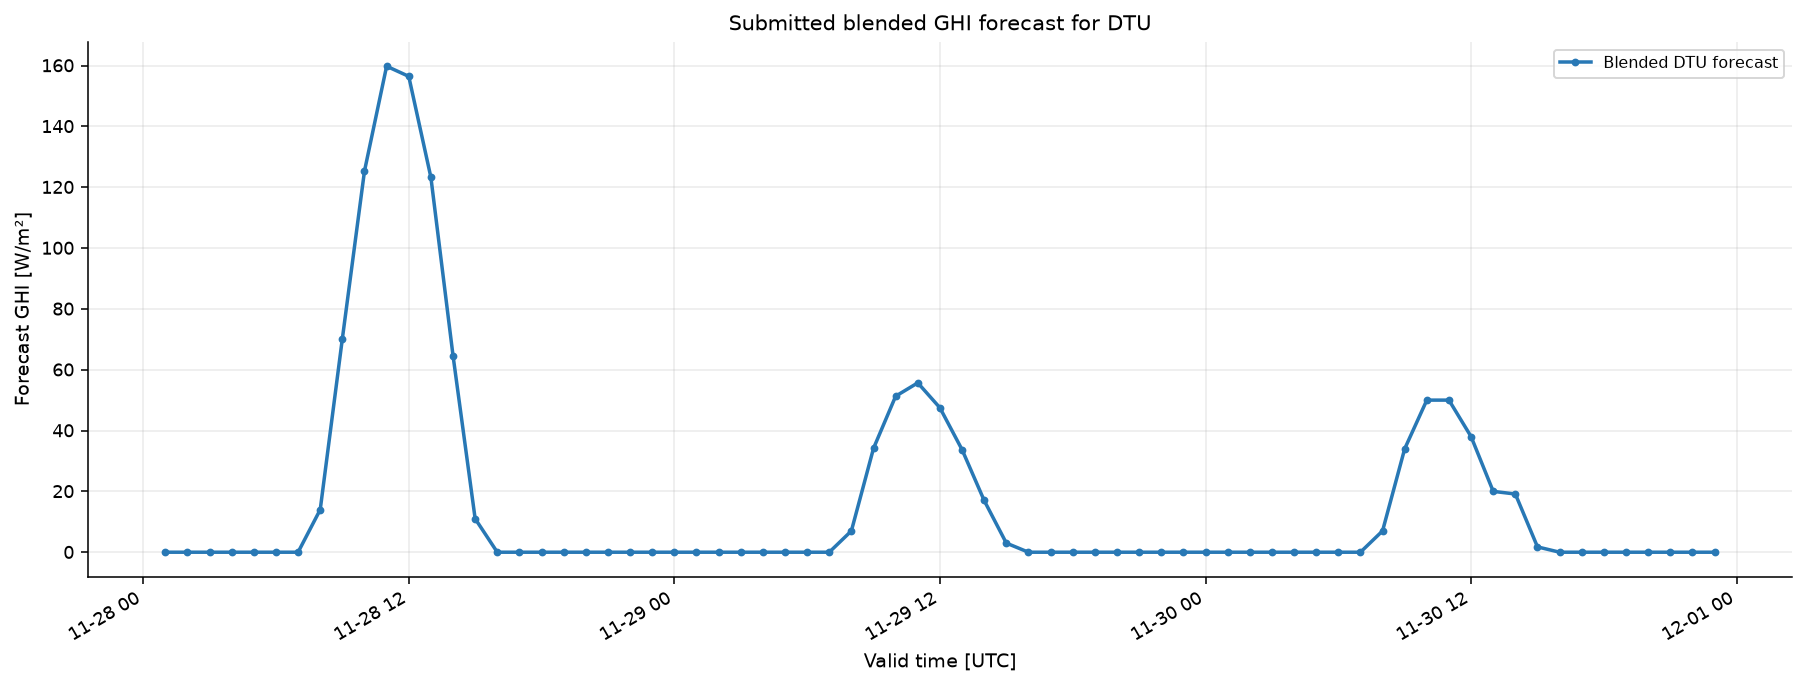

In [148]:
import pandas as pd
import matplotlib.pyplot as plt

plot_data = submission.copy()
plot_data["datetime"] = pd.to_datetime(plot_data["datetime"], utc=True)
plot_data["ghi_forecast"] = pd.to_numeric(plot_data["ghi_forecast"])

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    plot_data["datetime"],
    plot_data["ghi_forecast"],
    color="#2878B5",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="Blended DTU forecast",
)

ax.set_title("Submitted blended GHI forecast for DTU")
ax.set_xlabel("Valid time [UTC]")
ax.set_ylabel("Forecast GHI [W/m²]")
ax.grid(alpha=0.25)
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

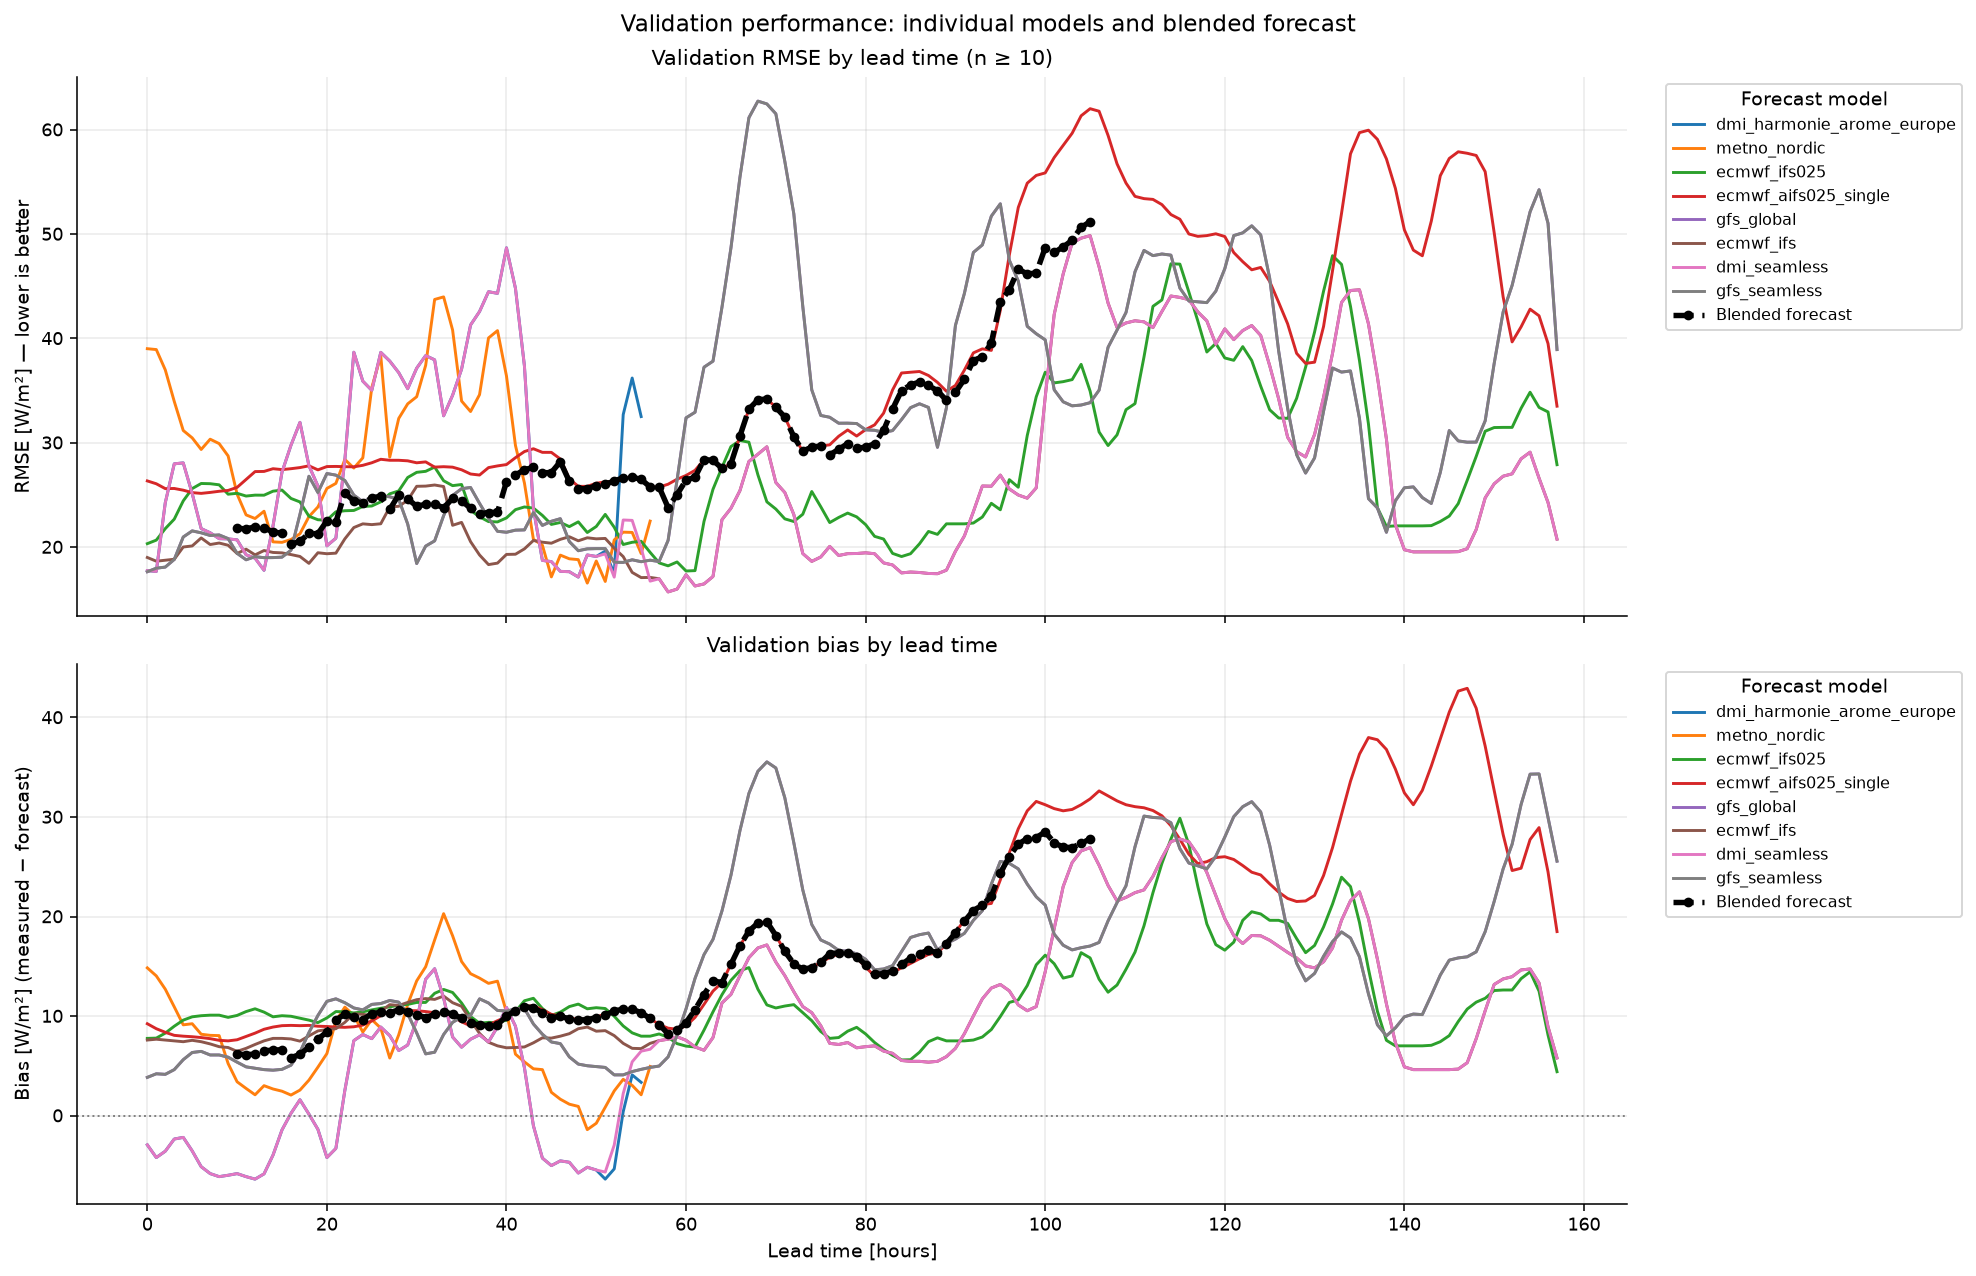

In [150]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Beregn blendet på valideringsdata med den accepterede vægtplan.
blended_validation = our_blend_by_lead_time(
    forecast_validation,
    weight_schedule,
)

validation_forecasts = dict(forecast_validation)
validation_forecasts["Blended forecast"] = blended_validation

measured = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

# Beregn RMSE og bias separat for hver model og lead time.
score_rows = []

for model, forecast in validation_forecasts.items():
    for lead_column in forecast.columns:
        try:
            lead_time = int(round(float(lead_column)))
        except (TypeError, ValueError):
            continue

        prediction = forecast[lead_column].replace(
            [np.inf, -np.inf], np.nan
        )
        observation = measured.reindex(prediction.index)

        pairs = pd.concat(
            [
                prediction.rename("forecast"),
                observation.rename("measured"),
            ],
            axis=1,
        ).dropna()

        if pairs.empty:
            continue

        # Bias følger funktionen: measured − forecast.
        error = pairs["measured"] - pairs["forecast"]

        score_rows.append({
            "model": model,
            "lead_time_h": lead_time,
            "n": len(pairs),
            "rmse": np.sqrt(np.mean(error**2)),
            "bias": error.mean(),
        })

scores = pd.DataFrame(score_rows)

# Skjul værdier med meget få observationer.
min_samples = 10
scores.loc[scores["n"] < min_samples, ["rmse", "bias"]] = np.nan

# Tegn RMSE og bias i to overskuelige paneler.
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

colors = plt.get_cmap("tab10").colors
models = list(validation_forecasts)

for i, model in enumerate(models):
    model_scores = (
        scores.loc[scores["model"] == model]
        .sort_values("lead_time_h")
    )

    if model_scores.empty:
        continue

    is_blend = model == "Blended forecast"
    color = "black" if is_blend else colors[i % len(colors)]
    linewidth = 2.8 if is_blend else 1.5
    linestyle = "--" if is_blend else "-"

    axes[0].plot(
        model_scores["lead_time_h"],
        model_scores["rmse"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

    axes[1].plot(
        model_scores["lead_time_h"],
        model_scores["bias"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

axes[0].set_title(f"Validation RMSE by lead time (n ≥ {min_samples})")
axes[0].set_ylabel("RMSE [W/m²] — lower is better")
axes[0].grid(alpha=0.25)
axes[0].legend(title="Forecast model", bbox_to_anchor=(1.02, 1), loc="upper left")

axes[1].axhline(0, color="grey", linewidth=1, linestyle=":")
axes[1].set_title("Validation bias by lead time")
axes[1].set_ylabel("Bias [W/m²] (measured − forecast)")
axes[1].set_xlabel("Lead time [hours]")
axes[1].grid(alpha=0.25)
axes[1].legend(title="Forecast model", bbox_to_anchor=(1.02, 1), loc="upper left")

fig.suptitle("Validation performance: individual models and blended forecast")
plt.show()

After having found our weight blend, we make a new split and test our model on the latest data 

Training ends before:   2026-11-17 14:00:00+00:00
Validation period:     2026-11-17 14:00:00+00:00 to before 2026-11-20 14:00:00+00:00
Test period starts:    2026-11-20 14:00:00+00:00
Test period ends:      2026-11-23 14:00:00+00:00


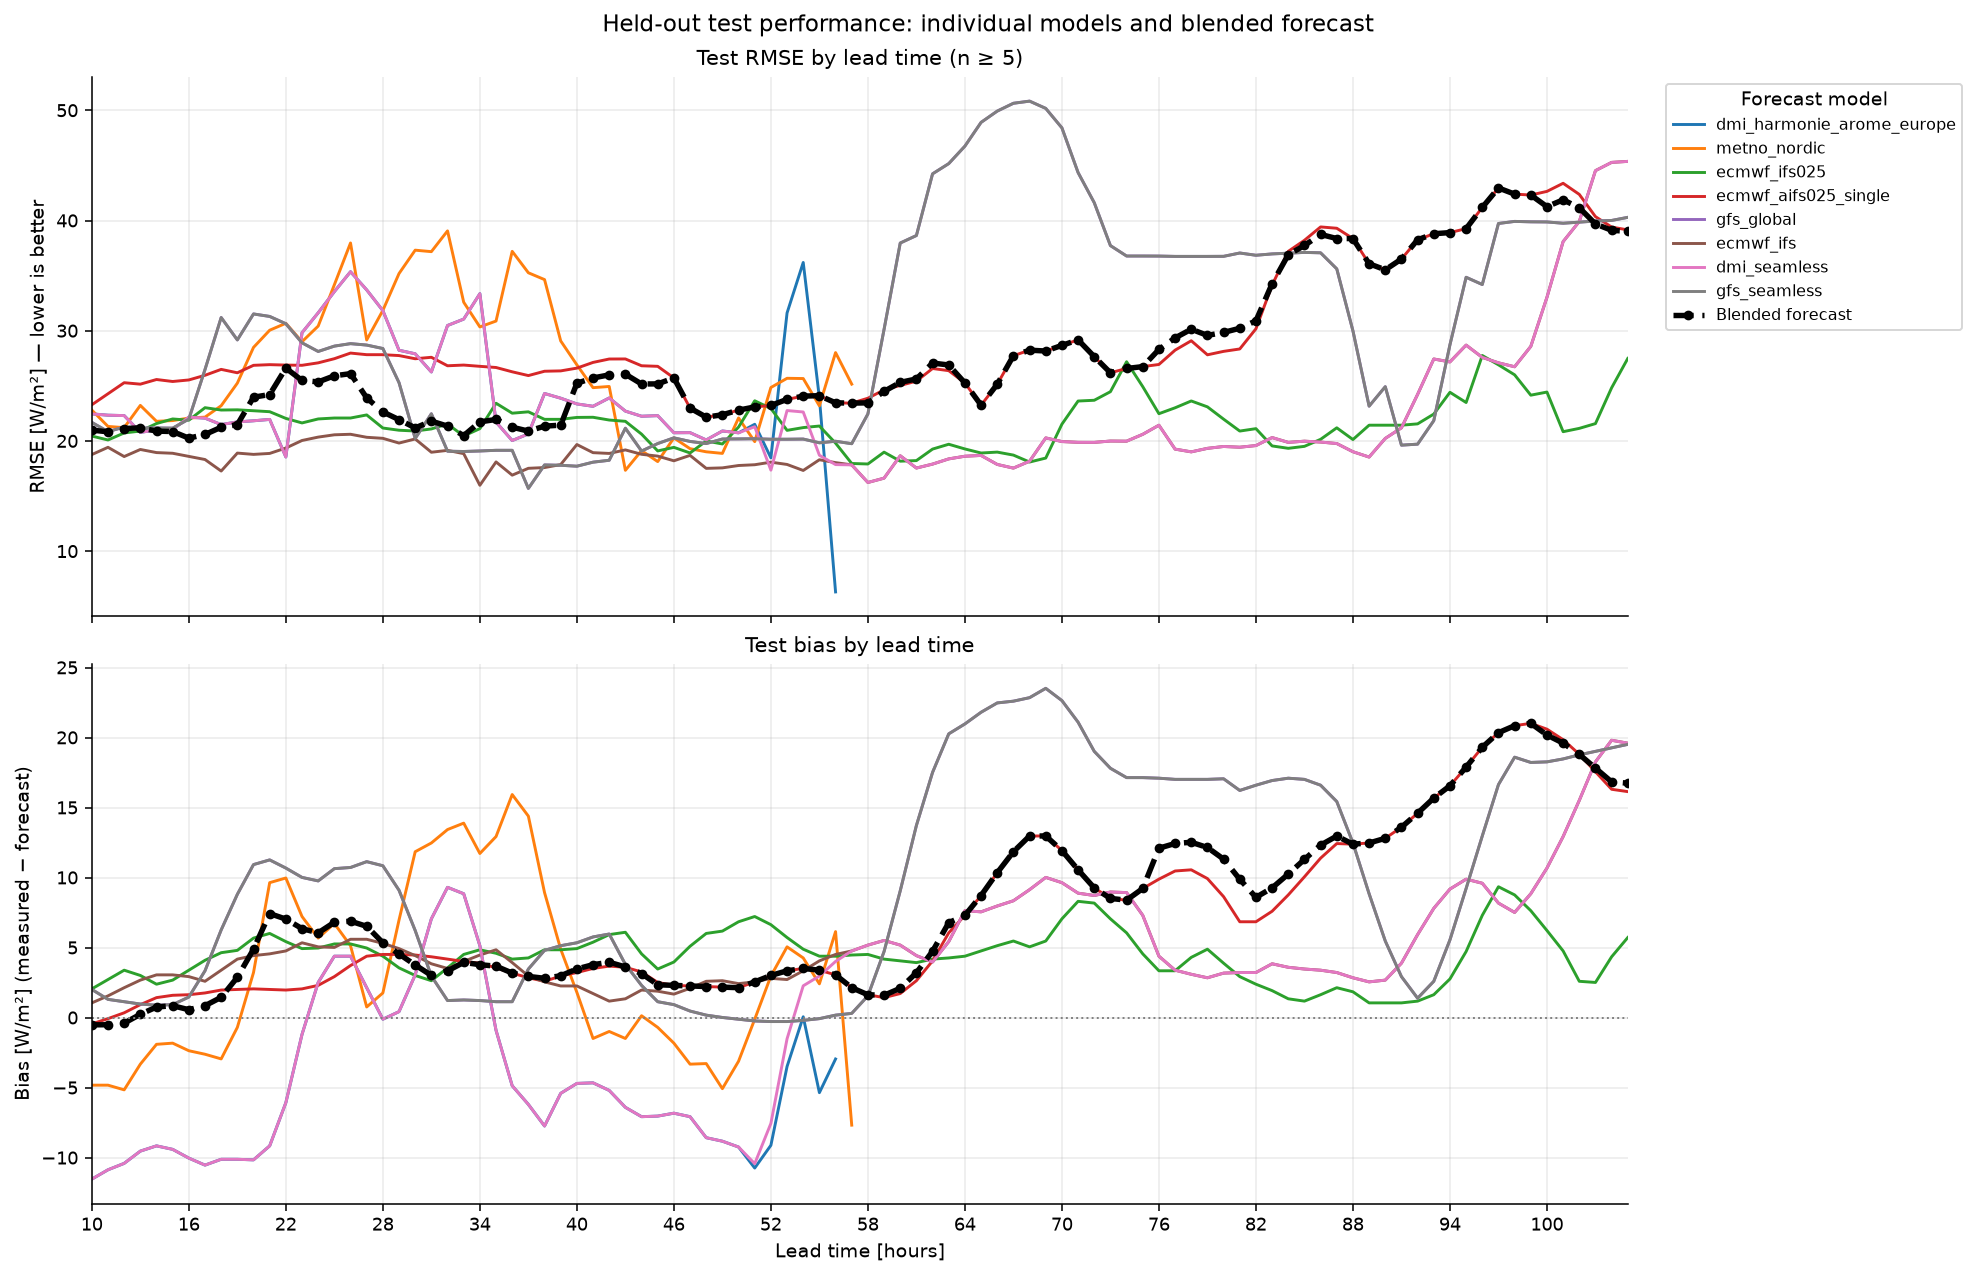

In [154]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Brug samme lead-time-intervaller som i afleveringsmodellen.
backtest_intervals = [
    (first, first + 5)
    for first in range(10, 106, 6)
]

# Find gyldige tidspunkter med både måling og mindst én forecast.
backtest_measured = (
    hourly_dmi["ghi_measured"]
    .replace([np.inf, -np.inf], np.nan)
)

backtest_forecast_times = pd.Index([])
for forecast in forecast_unstacked.values():
    backtest_forecast_times = backtest_forecast_times.union(forecast.index)

backtest_matched_times = (
    backtest_measured.index[backtest_measured.notna()]
    .intersection(backtest_forecast_times)
    .sort_values()
)

if len(backtest_matched_times) < 10:
    raise ValueError("For få matched tidspunkter til en train/validation/test-split.")

# Kronologisk split: 60 % træning, 20 % validation, 20 % test.
train_end_position = int(len(backtest_matched_times) * 0.60)
test_start_position = int(len(backtest_matched_times) * 0.80)

validation_start = backtest_matched_times[train_end_position]
test_start = backtest_matched_times[test_start_position]

backtest_train = {
    model: forecast.loc[forecast.index < validation_start].copy()
    for model, forecast in forecast_unstacked.items()
}

backtest_validation = {
    model: forecast.loc[
        (forecast.index >= validation_start)
        & (forecast.index < test_start)
    ].copy()
    for model, forecast in forecast_unstacked.items()
}

backtest_test = {
    model: forecast.loc[forecast.index >= test_start].copy()
    for model, forecast in forecast_unstacked.items()
}

print(f"Training ends before:   {validation_start}")
print(f"Validation period:     {validation_start} to before {test_start}")
print(f"Test period starts:    {test_start}")
print(f"Test period ends:      {backtest_matched_times[-1]}")

# Vælg vægte på træningsdata, og brug validation til at acceptere/forkaste blendet.
backtest_weight_schedule, backtest_diagnostics, _ = (
    fit_blend_weights_by_lead_time(
        backtest_train,
        backtest_validation,
        hourly_dmi,
        intervals=backtest_intervals,
        min_train_samples=30,
        min_validation_samples=10,
    )
)

# Først nu anvendes den valgte vægtplan på det urørte testdatasæt.
backtest_blend = our_blend_by_lead_time(
    backtest_test,
    backtest_weight_schedule,
)

test_forecasts = dict(backtest_test)
test_forecasts["Blended forecast"] = backtest_blend

# Beregn RMSE og bias for hver model og lead time på testdata.
test_score_rows = []

for model, forecast in test_forecasts.items():
    for lead_column in forecast.columns:
        try:
            lead_time = int(round(float(lead_column)))
        except (TypeError, ValueError):
            continue

        if not 10 <= lead_time <= 105:
            continue

        prediction = forecast[lead_column].replace(
            [np.inf, -np.inf], np.nan
        )
        observation = backtest_measured.reindex(prediction.index)

        pairs = pd.concat(
            [
                prediction.rename("forecast"),
                observation.rename("measured"),
            ],
            axis=1,
        ).dropna()

        if pairs.empty:
            continue

        error = pairs["measured"] - pairs["forecast"]

        test_score_rows.append({
            "model": model,
            "lead_time_h": lead_time,
            "n": len(pairs),
            "rmse": np.sqrt(np.mean(error**2)),
            "bias": error.mean(),
        })

test_scores = pd.DataFrame(test_score_rows)

if test_scores.empty:
    raise ValueError("Ingen matched forecast- og måledata i testperioden.")

# Skjul lead times med få observationer.
min_test_samples = 5
test_scores.loc[
    test_scores["n"] < min_test_samples,
    ["rmse", "bias"],
] = np.nan

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

colors = plt.get_cmap("tab10").colors

for i, model in enumerate(test_forecasts):
    model_scores = (
        test_scores.loc[test_scores["model"] == model]
        .sort_values("lead_time_h")
    )

    if model_scores.empty:
        continue

    is_blend = model == "Blended forecast"
    color = "black" if is_blend else colors[i % len(colors)]
    linewidth = 2.8 if is_blend else 1.5
    linestyle = "--" if is_blend else "-"

    axes[0].plot(
        model_scores["lead_time_h"],
        model_scores["rmse"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

    axes[1].plot(
        model_scores["lead_time_h"],
        model_scores["bias"],
        color=color,
        linewidth=linewidth,
        linestyle=linestyle,
        marker="o" if is_blend else None,
        markersize=4,
        label=model,
    )

axes[0].set_title(
    f"Test RMSE by lead time (n ≥ {min_test_samples})"
)
axes[0].set_ylabel("RMSE [W/m²] — lower is better")
axes[0].grid(alpha=0.25)
axes[0].legend(
    title="Forecast model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

axes[1].axhline(0, color="grey", linewidth=1, linestyle=":")
axes[1].set_title("Test bias by lead time")
axes[1].set_ylabel("Bias [W/m²] (measured − forecast)")
axes[1].set_xlabel("Lead time [hours]")
axes[1].set_xlim(10, 105)
axes[1].set_xticks(range(10, 106, 6))
axes[1].grid(alpha=0.25)

fig.suptitle(
    "Held-out test performance: individual models and blended forecast"
)
plt.show()